# Energy Wall — projection 2024-2035 de la consommation électrique des datacenters

## 0. Objet et périmètre

- **Grandeur** : consommation électrique **totale** des datacenters (IA et non-IA), **monde**,
  pas **annuel**, 2024-2035. Aucune interpolation annuel -> mensuel.
- **Scénarios** : pessimiste (= consommation haute), normal, optimiste (= consommation basse).
  Ce sont des projections directes de jeux cohérents de bornes, **comparées** (et non calées)
  aux bornes IEA 2035.
- **Sorties** : TWh, CO2e (scope 2 location-based, Mt) et eau consommée (hm³).
- Tous les chiffres ci-dessous sont produits par des cellules de code à partir de
  `data/sources.yaml` et `data/params.yaml` via le paquet `energywall` ; le texte ne cite aucun
  chiffre du modèle ; les seuls chiffres du texte sont des faits de la littérature, avec leur
  statut.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from energywall import backtest as B
from energywall import incertitude as U
from energywall import model as M
from energywall import report as R
from energywall import sources as S

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 200)

## 1. Sources, origines et biais

Point central du projet : chaque valeur remonte à une source du registre, et chaque source porte
son origine (type d'acteur), son mode de lecture, son intérêt potentiel et ses biais déclarés.
Ce qui n'est pas qualifié est **compté et affiché** (`a_qualifier`, `indetermine`) ; les intérêts
et biais déclarés inconnus (« NT » = non trouvé) sont comptés à part (`n_interet_nt`,
`n_biais_nt`) : jamais masqués.

In [2]:
S.validate()
print("Validation du registre et des paramètres : OK")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(R.registre())

Validation du registre et des paramètres : OK


,organisation,type_acteur,statut_lecture,methode,periode_donnees,perimetre,interet
id,,,,,,,
iea_energy_ai_2025,IEA,agence_publique,lu_source,modelisation,2024 (415 TWh) ; 2030 Base (945 TWh) ; 2035 par scénario,"Consommation électrique des datacenters, monde (US 45 %, Chine 25 %, Europe 15 % en 2024) ; période annuelle",Agence intergouvernementale (32 membres) ; financement NT (non documenté) ; entrées de projection = livraisons de serveurs annoncées par l'industrie [V]
iea4e_2025,IEA-4E,agence_publique,lu_source,estimation_secondaire,"Dispersion de la littérature sur les datacenters au total : 2020 de moins de 200 à 1 200 TWh ; 2030 de 210 à 7 900 TWh, facteur ~40 [V, p. iv, p. 12] ; monde 2023 : 300-380 TWh hors crypto [V, p. v] ; IA 2023 : « 10-50 TWh » (5-15 % de la consommation des datacenters) et projection de la littérature 200-900 TWh en 2030 [V, p. vi] ; part entraînement 20-40 % de l'énergie ML, données Meta/Google <= 2022 [V, p. 29] ; croissance mondiale depuis 2018 : +50-80 %, soit 8-13 %/an [V, p. 43]","Revue critique (plus de 100 sources, plus de 200 scénarios, 2010-2040 [S], non relevé dans la lecture du PDF) des modèles de consommation des datacenters au total, hors crypto pour les chiffres monde ; pas de l'IA seule ; PDF de 72 pages lu en entier par nous (pagination imprimée citée) ; les chiffres de tiers (Meta, Google, LBNL, IEA 2024a) sont repris via la revue : [S] pour eux","Rapport commandé par la plateforme EDNA du 4E TCP (programme de collaboration « sous les auspices de l'IEA », juridiquement autonome ; 14 pays et la Commission européenne) à deux auteurs, George Kamiya (expert indépendant, Royaume-Uni) et Vlad Coroamă (Roegen Centre for Sustainability, Suisse) ; vues propres aux auteurs [V, p. 2 de couverture, p. i] ; montant et conditions du financement NT (non indiqués dans le PDF) ; type_acteur agence_publique = valeur d'enum la plus proche, discutable (programme de collaboration d'agence, auteurs indépendants mandatés : inférence)"
nature_2026,Nature (revue),academique_revu,paywall,estimation_secondaire,IA ~118 TWh (2024) ; 239-295 TWh (2030),"Datacenters IA, agrégation top-down des 6 principaux hyperscalers, recoupée avec l'IEA ; ~1 % de l'électricité mondiale","NT : article inaccessible (paywall), auteurs et financement non lus"
morrison_2025,Morrison et al.,preprint,lu_source,declaratif,"Entraînement de modèles OLMo sur deux clusters (Jupiter, Augusta)","Deux clusters de recherche, Jupiter (Texas, Austin Energy) et Augusta (Iowa) : PUE fournis par les hébergeurs (Jupiter entre 1,1 et 1,2, retenu 1,2 ; Augusta 1,12 en moyenne glissante 12 mois) ; WUE sur site supposé 0 ; WUE hors site (EWIF) 1,29 L/kWh (Jupiter) et 3,10 L/kWh (Augusta), hypothèses du papier d'après Reig et al. 2020 (WRI) ; fabrication amortie sur 4 ans",Auteurs AI2/CMU ; financement NT ; pas de conflit commercial identifié ; PUE et intensité fournis par les hébergeurs (déclaratif)
uptime,Uptime Institute,entreprise_tech,relais,declaratif,"PUE 1,56 (2024) ; 1,54 (2025) ; stable depuis ~2018","PUE opérationnel déclaré du plus grand datacenter de chaque répondant (mise à jour oct. 2025, n=681) ; traitement des hyperscalers non précisé ; rapport complet payant","Entreprise commerciale (conseil, certification Tier = revenu principal selon la critique de Switch), rapport payant ; propriétaire 451 Group (NT sur la structure actuelle après 2019) ; type_acteur entreprise_tech = valeur d'enum la plus proche (conseil/certification)"
epoch,Epoch AI,think_tank_ong,relais,estimation_secondaire,Un modèle = une date (pas de série régulière) ; tendances de compute et d'efficacité du matériel,"Modèles de pointe et notables, matériel ML, sites AI Data Centers (couverture estimée 44 %, IC90 23-81 %) ; les tendances chiffrées citées sont secondaires","Association à but non lucratif financée surtout par Coefficient Giving (ex-Open Philanthropy) et donateurs privés ; partenariats avec OpenAI, Google DeepMind, xAI, Anthropic ; actions semi-conducteurs/I

### 1.1 Origine et mode de lecture : type d'acteur × statut de lecture

In [3]:
display(R.acteur_x_lecture())

statut_lecture,lu_source,paywall,pdf_illisible,relais,total
type_acteur,,,,,
academique_revu,1,1,0,1,3
agence_publique,3,0,0,1,4
agregateur,0,0,0,1,1
entreprise_tech,2,0,0,2,4
preprint,4,0,0,1,5
statistique_publique,1,0,0,0,1
think_tank_ong,1,0,1,1,3
total,12,1,1,7,21


### 1.2 Biais déclarés : par sens, puis par grandeur

In [4]:
display(R.biais_par_sens().to_frame("n"))
display(R.biais_sens_x_grandeur())

,n
sens,
indetermine,42
sous-estimation,15
surestimation,10


sens,indetermine,sous-estimation,surestimation,total
grandeur,,,,
CI mondial 2025,1,0,0,1
CI_ref,2,0,0,2
CI_ref (par rapport aux facteurs directs),0,0,1,1
EWIF,2,0,0,2
E_DC0,1,0,0,1
"E_DC0 (415 TWh, 2024)",1,0,0,1
E_DC0 (si comparé à l'IEA),1,0,0,1
FLOP/token d'inférence (g_fpt_net),0,1,0,1
PUE du parc total (PUE_2024),0,1,0,1


### 1.3 Sources bloquées (pdf illisible, paywall, introuvable) et relations [NT]

Une source bloquée ne peut pas porter une borne de statut V ; les relations [NT] ne sont pas
revérifiées à la source.

In [5]:
print("Sources bloquées :")
display(R.sources_bloquees().set_index("id"))
print("Relations / valeurs marquées [NT] (non revérifiées) :")
with pd.option_context("display.max_colwidth", None):
    display(R.relations_nt().set_index("source"))
print("Paramètres dont une borne repose sur une relation [NT] (6ND / 2N) :")
print(", ".join(R.params_nt()))

Sources bloquées :


,organisation,statut_lecture
id,,
nature_2026,Nature (revue),paywall
shift_project_2025,The Shift Project,pdf_illisible


Relations / valeurs marquées [NT] (non revérifiées) :


,sens,grandeur,description
source,,,
kaplan_2020,indetermine,relation 6ND / 2N,Relation C~6ND et ~2N FLOP/token d'inférence : revérifiée à la source [V ar5iv] (N = paramètres hors plongements) ; pertinence pour les modèles à experts (N_act) non traitée dans le papier [NT]
hoffmann_2022,indetermine,relation 6ND / 20 tokens par paramètre,"6ND revérifiée comme approximation citée de Kaplan [S, résumé de l'outil sur ar5iv] ; 20 tokens/paramètre : non énoncé tel quel dans l'article, déduit du tableau 3 [inférence] [NT], optimum de calcul pour l'entraînement seul"
de_vries_2023,indetermine,consommation IA 2027,"Ne modélise pas l'efficacité (critique de jugement, non vérifiée [NT]) ; de Vries estime par ailleurs l'IEA trop basse : critiques de sens opposés"


Paramètres dont une borne repose sur une relation [NT] (6ND / 2N) :
C_train_2024, N_act


### 1.4 Zones non qualifiées (rapport de qualification, affiché tel quel)

`n_interet_nt` / `sources_interet_nt` : intérêts inconnus (NT) ; `n_biais_nt` : biais dont la
description porte une inconnue (NT) ; `n_interet_a_qualifier` : intérêts encore à qualifier.

In [6]:
rapport = S.qualification_report()
for cle, val in rapport.items():
    print(f"{cle:<28} {val}")

n_sources                    21
n_biais                      67
n_biais_a_qualifier          0
n_sens_indetermine           42
n_interet_a_qualifier        0
n_interet_nt                 16
sources_interet_nt           ['arxiv_2606_21760', 'bloom', 'cso_irlande', 'de_vries_2023', 'google_2025', 'hoffmann_2022', 'iea4e_2025', 'iea_energy_ai_2025', 'kaplan_2020', 'mistral_2025', 'morrison_2025', 'nature_2026', 'owid_2026', 'ren_2023', 'shift_project_2025', 'uptime']
n_biais_nt                   3
n_type_acteur_non_qualifie   3
sources_sens_indetermine     ['arxiv_2606_21760', 'bloom', 'cso_irlande', 'de_vries_2023', 'ember_2025', 'epoch', 'google_2025', 'hoffmann_2022', 'iea4e_2025', 'iea_energy_ai_2025', 'iea_key_questions_2026', 'kaplan_2020', 'lbnl_2024', 'mistral_2025', 'morrison_2025', 'nature_2026', 'owid_2026', 'ren_2023', 'shift_project_2025', 'uptime']
sources_non_lues             ['de_vries_2023', 'epoch', 'hoffmann_2022', 'lbnl_2024', 'nature_2026', 'openrouter', 'owid_2026', 

## 2. Paramètres et traçabilité

Chaque borne (low / central / high) porte une valeur, un statut et des `source_ids` :
**V** lu à la source, **S** via relais, **D** dérivé d'une source, **H** hypothèse justifiée.
Les plages H de croissance encadrent des ordres de grandeur IEA : la circularité est assumée,
ce n'est pas une mesure.

In [7]:
print("Bornes par statut :")
display(R.bornes_par_statut())
print("Paramètres dont les trois bornes sont H :")
print(", ".join(R.params_tout_h()))

Bornes par statut :


,n,part_%
statut,,
V,12,17.39
S,1,1.45
D,9,13.04
H,47,68.12


Paramètres dont les trois bornes sont H :


C_train_2024, N_act, PUE_2035, Tokens_2024, eff_eff, g_Ctrain_2025, g_Ctrain_2035, g_cap, g_conv, g_fpt_net, g_tok_2025, g_tok_2035


In [8]:
with pd.option_context("display.max_rows", None, "display.max_colwidth", 110):
    display(R.tracabilite())

unite valeur statut                  source_ids  \
param         borne                                                                                                             
E_DC0         low                                                               TWh    415      V          iea_energy_ai_2025   
              central                                                           TWh    415      V          iea_energy_ai_2025   
              high                                                              TWh    415      V          iea_energy_ai_2025   
s_AI          low                                                                 -   0.05      D                  iea4e_2025   
              central                                                             -   0.15      H                               
              high                                                                -   0.28      D                 nature_2026   
s_train       low                                                                 -    0.2      D                  iea4e_2025   
              central                                                             -   0.35      H                  iea4e_2025   
              high                                                                -    0.4      D                  iea4e_2025   
PUE_2024      low                                                                 -    1.2      D               morrison_2025   
              central                                                             -    1.4      H                               
              high                                                                -   1.56      S                      uptime   
g_conv        low                                                           taux/an   0.02      H          iea_energy_ai_2025   
              central                                                       taux/an   0.03      H          iea_energy_ai_2025   
              high                                                          taux/an   0.04      H          iea_energy_ai_2025   
g_Ctrain_2025 low                                                        facteur/an    1.6      H                       epoch   
              central                                                    facteur/an    1.8      H                       epoch   
              high                                                       facteur/an    1.9      H                       epoch   
g_Ctrain_2035 low                                                        facteur/an   1.15      H                               
              central                                                    facteur/an    1.2      H                               
              high                                                       facteur/an   1.25      H                               
g_tok_2025    low                                                        facteur/an    1.9      H                  openrouter   
              central                                                    facteur/an      2      H                  openrouter   
              high                                                       facteur/an    2.2      H                  openrouter   
g_tok_2035    low                                                        facteur/an    1.2      H                               
              central                                                    facteur/an    1.3      H                               
              high                                                       facteur/an   1.35      H                               
g_fpt_net     low                                                        facteur/an   0.97      H                               
              central                                                    facteur/an      1      H                               
              high                                                       facteu

## 3. Modèle

Identité de Kaya exprimée en taux de croissance, année de base 2024, $n = t - 2024$.

**Facteur de croissance décroissante** (pour $g_{C_{train}}$ et $g_{tok}$) : taux logarithmique
par étape décroissant linéairement de $\ln g_{2025}$ à $\ln g_{2035}$,
$F(t) = \exp\left(\sum_{k=2024}^{t-1} r(k)\right)$, $F(2024) = 1$.

**PUE** linéaire entre $PUE_{2024}$ et $PUE_{2035}$ ; $p(t) = PUE(t)/PUE_{2024}$.
**Efficacité du parc** : $f_{hw}(t) = 2^{n/T_{d,parc}}$.

$$E_{conv}(t) = E_{DC0}\,(1 - s_{AI})\,(1 + g_{conv})^n\,p(t)$$
$$E_{train}(t) = E_{DC0}\,s_{AI}\,s_{train}\,\frac{F_{C_{train}}(t)}{f_{hw}(t)}\,p(t)$$
$$E_{inf}(t) = E_{DC0}\,s_{AI}\,(1 - s_{train})\,\frac{F_{tok}(t)\,g_{fpt,net}^{\,n}}{f_{hw}(t)}\,p(t)$$
$$E_{dem} = E_{conv} + E_{train} + E_{inf}, \qquad E_{dem}(2024) = E_{DC0}$$

**CO2e, scope 2 location-based** (1 TWh × 1 g/kWh = 1 kt) :
$CO2(t) = E_{dem}(t)\,CI(t) / 1000$ en Mt, avec
$CI(t) = CI_{ref}\,(1 - d_{CI})^{t - t_{ref}}$ (moyenne mondiale), où $t_{ref}$ est
`annee_ref_CI`, lue dans `data/params.yaml`.

**Eau consommée** (1 TWh × 1 L/kWh = 1 hm³) :
$W(t) = \dfrac{E_{dem}(t)}{PUE(t)}\,WUE_{site} + E_{dem}(t)\,EWIF$.

**Mur (stress test séparé)** : $E_{cap}(t) = E_{DC0}\,(1 + g_{cap})^n$,
$E_{wall}(t) = \max(0,\ E_{dem}(t) - E_{cap}(t))$, pour chaque borne de $g_{cap}$.

**Calage = diagnostic** : `implied_param` résout $E_{dem}(2035) = $ cible IEA pour $g_{tok,2025}$
(brentq sur un bracket explicite) ; il n'est **jamais** injecté dans les scénarios.

**Contrôle bottom-up 2024** (affiché, non utilisé) :
$E_{bu} = \dfrac{C_{train,2024} + 2 N_{act}\,Tokens_{2024}}{eff_{eff}}\,PUE_{2024}$,
comparé à $E_{DC0}\,s_{AI}$. $C_{train,2024}$ est un paramètre H (ordre de grandeur de $6ND$,
relation 6ND vérifiée dans Kaplan) ; $N_{act}$ reste en partie [NT]
(pertinence pour les modèles à experts non traitée, « 20 tokens par paramètre » de Hoffmann non
énoncé tel quel). Les relations 6ND et 2N FLOP/token sont vérifiées dans Kaplan.

## 4. Scénarios : TWh, CO2e, eau

In [9]:
res = M.run_scenarios()
cibles = S.raw_params()["cibles_iea"]
UNITES = {"E_dem": "TWh", "CO2_Mt": "Mt CO2e", "W_hm3": "hm³"}

for col, unite in UNITES.items():
    print(f"{col} ({unite})")
    display(res[col].unstack(level="scenario")[list(M.SCENARIOS)])

E_dem (TWh)


scenario,pessimiste,normal,optimiste
annee,,,
2024,415.00,415.00,415.00
2025,468.72,452.68,436.99
2026,544.13,500.10,461.09
2027,647.29,557.57,485.88
2028,783.18,624.07,509.44
2029,953.96,696.95,529.58
2030,"1,157.04",771.91,544.25
2031,"1,383.65",843.28,551.85
2032,"1,618.38",904.79,551.61


CO2_Mt (Mt CO2e)


scenario,pessimiste,normal,optimiste
annee,,,
2024,191.03,192.96,195.95
2025,214.67,207.33,200.14
2026,247.96,225.61,204.84
2027,293.50,247.76,209.38
2028,353.34,273.15,212.95
2029,428.24,300.48,214.73
2030,516.81,327.80,214.05
2031,614.94,352.74,210.53
2032,715.66,372.79,204.13


W_hm3 (hm³)


scenario,pessimiste,normal,optimiste
annee,,,
2024,"1,895.96",960.43,564.99
2025,"2,145.75","1,050.80",595.34
2026,"2,496.12","1,164.48",628.62
2027,"2,975.56","1,302.37",662.90
2028,"3,607.86","1,462.35",695.55
2029,"4,403.95","1,638.43",723.62
2030,"5,353.03","1,820.64",744.25
2031,"6,415.42","1,995.67",755.25
2032,"7,520.35","2,148.55",755.54


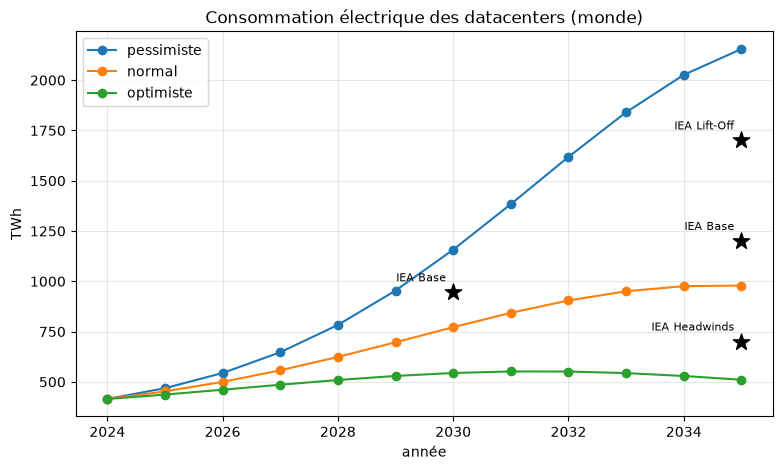

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for s in M.SCENARIOS:
    ax.plot(M.ANNEES, res.loc[s, "E_dem"], marker="o", label=s)
for c in cibles:
    ax.scatter([c["annee"]], [c["valeur"]], marker="*", s=150, color="k", zorder=3)
    ax.annotate(f"IEA {c['cas_iea']}", (c["annee"], c["valeur"]), textcoords="offset points",
                xytext=(-5, 8), fontsize=8, ha="right")
ax.set(xlabel="année", ylabel="TWh", title="Consommation électrique des datacenters (monde)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

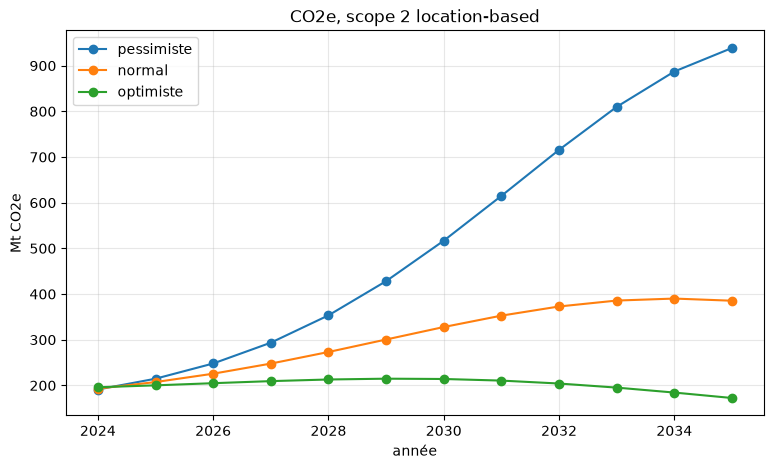

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for s in M.SCENARIOS:
    ax.plot(M.ANNEES, res.loc[s, "CO2_Mt"], marker="o", label=s)
ax.set(xlabel="année", ylabel="Mt CO2e", title="CO2e, scope 2 location-based")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

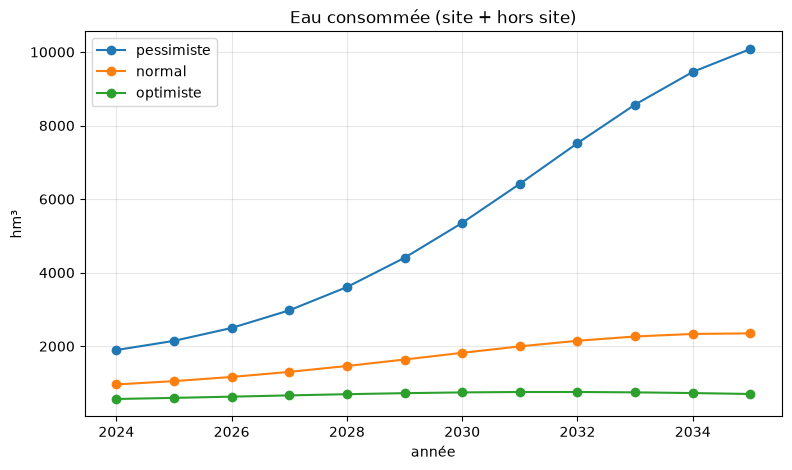

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
for s in M.SCENARIOS:
    ax.plot(M.ANNEES, res.loc[s, "W_hm3"], marker="o", label=s)
ax.set(xlabel="année", ylabel="hm³", title="Eau consommée (site + hors site)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 4.1 Écart 2035 au modèle vs bornes IEA (comparaison, pas calage)

In [13]:
ecarts = pd.DataFrame(
    {
        "modele_TWh": [res.loc[(s, M.ANNEE1), "E_dem"] for s in M.SCENARIOS],
        "cible_IEA_TWh": [M.cible_iea(s) for s in M.SCENARIOS],
    },
    index=pd.Index(M.SCENARIOS, name="scenario"),
)
ecarts["ecart_TWh"] = ecarts["modele_TWh"] - ecarts["cible_IEA_TWh"]
ecarts["ecart_%"] = 100 * ecarts["ecart_TWh"] / ecarts["cible_IEA_TWh"]
display(ecarts)

,modele_TWh,cible_IEA_TWh,ecart_TWh,ecart_%
scenario,,,,
pessimiste,"2,154.83","1,700.00",454.83,26.75
normal,978.79,"1,200.00",-221.21,-18.43
optimiste,510.57,700.00,-189.43,-27.06


### 4.2 Carbone incorporé du matériel IT (sous-ensemble du scope 3, ordre de grandeur)

Le carbone incorporé (fabrication) du matériel IT n'est **qu'un sous-ensemble** du scope 3 ;
ce n'est pas « le scope 3 ». Il est affiché **à part, jamais additionné** au CO2e scope 2
(location-based) des sections précédentes : aucune colonne « total ».

- **Paramètre** `r_s3` (hors scénarios et hors Monte Carlo) : incorporé / CO2e scope 2
  location-based, évalué à `CI_ref`. L'intensité incorporée par kWh (`r_s3` × `CI_ref`) est
  supposée **constante** (le matériel ne se décarbone pas avec le réseau) : biais assumé. Le
  ratio **effectif** `r_s3` × `CI_ref` / `CI(t)` croît donc avec la décarbonation du réseau.
- **Borne basse** [D, Morrison et al.] : 22 tCO2e de fabrication pour un total « ≥ 493 t » ;
  le « ≥ » en fait un majorant pour ce cluster ; il est retenu comme borne basse du secteur parce
  qu'il ne compte que les GPU (amortissement 4 ans). Rattacher 0,332 kg/kWh (cluster Jupiter) à
  l'ensemble des 493 t est notre hypothèse, non établie par la référence. Bornes centrale et
  haute : [H], choisies par nous, pas des mesures ; la
  haute couvre l'hôte, le stockage, le réseau, le refroidissement et les bâtiments, exclus des
  ACV. Le même ratio est appliqué au non-IA sans preuve.
- **Repères hyperscalers** (périmètre scope 3 complet) : Google ~73 % du total
  « ambition-based » [S], Facebook 2019 ×23 [V], Microsoft [S]. Ramenés à un dénominateur
  location-based avec les écarts location/market des refs (×1,4 à ×7,6) : la plage ≈ 0,36 à
  1,9 vient de Google seul (2,7/7,6 et 2,7/1,4) [D, notre calcul]. Facebook 2019
  ×23 [V] donnerait jusqu'à ≈ 16 avec le même facteur. Le scope 3 complet d'un hyperscaler est
  plus grand que cette plage.
- Lecture : un ordre de grandeur sur des bornes mal contraintes, pas une prévision. BLOOM : [NT].

In [14]:
annees_tab = [M.ANNEE0, M.ANNEES[len(M.ANNEES) // 2], M.ANNEE1]
tables = {s: M.carbone_incorpore(s) for s in M.SCENARIOS}
lignes = []
for s, t in tables.items():
    for a in annees_tab:
        ligne = {"scenario": s, "annee": a, "CO2e_scope2_Mt": t.loc[a, "CO2_Mt"]}
        for b in S.BORNES:
            ligne[f"incorpore_{b}_Mt"] = t.loc[a, f"CO2_incorpore_Mt_{b}"]
        for b in S.BORNES:
            ligne[f"ratio_effectif_{b}"] = t.loc[a, f"ratio_effectif_{b}"]
        lignes.append(ligne)
display(pd.DataFrame(lignes).set_index(["scenario", "annee"]))

intensite = pd.Series(
    {b: tables["normal"].loc[M.ANNEE0, f"intensite_incorporee_g_kwh_{b}"] for b in S.BORNES},
    name="intensite_incorporee_g_kWh (constante)",
)
display(intensite.to_frame())

CO2e_scope2_Mt  incorpore_low_Mt  incorpore_central_Mt  incorpore_high_Mt  ratio_effectif_low  ratio_effectif_central  ratio_effectif_high
scenario   annee                                                                                                                                            
pessimiste 2024           191.03              6.46                  9.50              28.51                0.03                    0.05                 0.15
           2030           516.81             18.02                 26.50              79.49                0.03                    0.05                 0.15
           2035           938.66             33.56                 49.35             148.04                0.04                    0.05                 0.16
normal     2024           192.96              6.46                  9.50              28.51                0.03                    0.05                 0.15
           2030           327.80             12.02                 17.68              53.03                0.04                    0.05                 0.16
           2035           385.41             15.24                 22.41              67.24                0.04                    0.06                 0.17
optimiste  2024           195.95              6.46                  9.50              28.51                0.03                    0.05                 0.15
           2030           214.05              8.48                 12.46              37.39                0.04                    0.06                 0.17
           2035           172.44              7.95                 11.69              35.08                0.05                    0.07                 0.20

,intensite_incorporee_g_kWh (constante)
low,15.57
central,22.90
high,68.70


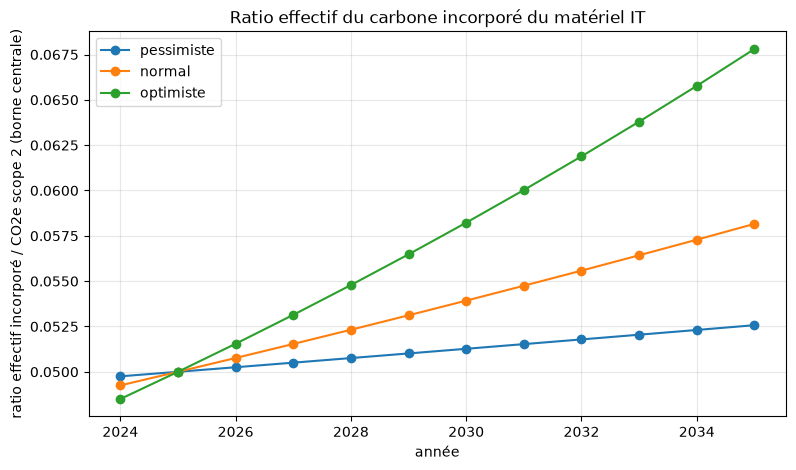

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
for s, t in tables.items():
    ax.plot(M.ANNEES, t["ratio_effectif_central"], marker="o", label=s)
ax.set(xlabel="année", ylabel="ratio effectif incorporé / CO2e scope 2 (borne centrale)",
       title="Ratio effectif du carbone incorporé du matériel IT")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [16]:
n, d = tables["normal"], M.ANNEE1
p_n = M.scenario_params("normal")
display(Markdown(
    f"**Lecture (scénario normal, {d})** : CO2e scope 2 = {n.loc[d, 'CO2_Mt']:.0f} Mt ; "
    f"carbone incorporé du matériel IT, à part = {n.loc[d, 'CO2_incorpore_Mt_low']:.1f} (basse), "
    f"{n.loc[d, 'CO2_incorpore_Mt_central']:.1f} (centrale), "
    f"{n.loc[d, 'CO2_incorpore_Mt_high']:.1f} (haute) Mt ; ratio effectif central "
    f"{n.loc[d, 'ratio_effectif_central']:.3f} en {d}, contre "
    f"{n.loc[int(p_n['annee_ref_CI']), 'ratio_effectif_central']:.3f} en {p_n['annee_ref_CI']:.0f} "
    f"(année de référence de `CI_ref`). Ordre de grandeur, jamais additionné au CO2e scope 2."
))

**Lecture (scénario normal, 2035)** : CO2e scope 2 = 385 Mt ; carbone incorporé du matériel IT, à part = 15.2 (basse), 22.4 (centrale), 67.2 (haute) Mt ; ratio effectif central 0.058 en 2035, contre 0.050 en 2025 (année de référence de `CI_ref`). Ordre de grandeur, jamais additionné au CO2e scope 2.

## 5. Diagnostic de calage et contrôle bottom-up

Pour chaque scénario, quelle valeur de $g_{tok,2025}$ ferait coïncider $E_{dem}(2035)$ avec la
cible IEA ? Le drapeau dit si cette valeur tombe dans la plage déclarée [low ; high].
C'est un **diagnostic** : le modèle n'est pas recalé.

In [17]:
table = S.load_params().set_index(["param", "borne"])["valeur"]
lignes = []
for s in M.SCENARIOS:
    propre = M.scenario_params(s)["g_tok_2025"]
    try:
        x, dans = M.implied_param(s, M.cible_iea(s))
        lignes.append({"scenario": s, "g_tok_2025_scenario": propre, "g_tok_2025_implique": x,
                       "dans_plage": dans})
    except M.CibleInatteignable as e:
        lignes.append({"scenario": s, "g_tok_2025_scenario": propre,
                       "g_tok_2025_implique": float("nan"), "dans_plage": False})
        print(f"{s} : {e}")
diag = pd.DataFrame(lignes).set_index("scenario")
for borne in S.BORNES:
    diag[f"plage_{borne}"] = table[("g_tok_2025", borne)]
display(diag)

,g_tok_2025_scenario,g_tok_2025_implique,dans_plage,plage_low,plage_central,plage_high
scenario,,,,,,
pessimiste,2.20,2.06,True,1.90,2.00,2.20
normal,2.00,2.15,True,1.90,2.00,2.20
optimiste,1.90,2.28,False,1.90,2.00,2.20


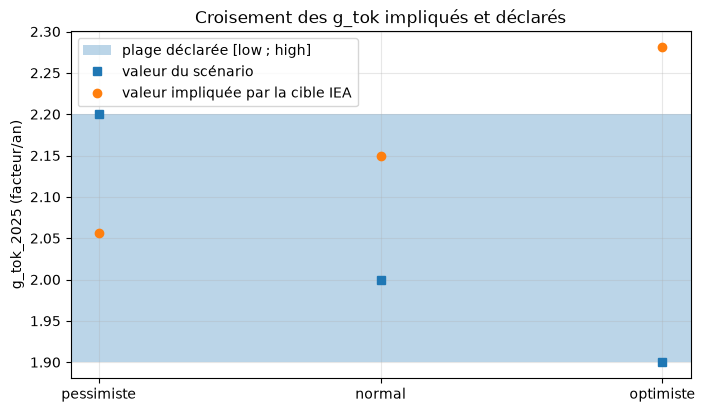

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = list(range(len(M.SCENARIOS)))
ax.axhspan(table[("g_tok_2025", "low")], table[("g_tok_2025", "high")], alpha=0.3,
           label="plage déclarée [low ; high]")
ax.plot(pos, diag["g_tok_2025_scenario"], "s", label="valeur du scénario")
ax.plot(pos, diag["g_tok_2025_implique"], "o", label="valeur impliquée par la cible IEA")
ax.set_xticks(pos, M.SCENARIOS)
ax.set(ylabel="g_tok_2025 (facteur/an)", title="Croisement des g_tok impliqués et déclarés")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [19]:
ordre_impl = list(diag["g_tok_2025_implique"].sort_values().index)
ordre_scen = list(diag["g_tok_2025_scenario"].sort_values().index)
chevauche = diag["g_tok_2025_implique"].between(
    diag["g_tok_2025_scenario"].min(), diag["g_tok_2025_scenario"].max()
)
print("Ordre croissant des g_tok impliqués :", ordre_impl)
print("Ordre croissant des g_tok des scénarios :", ordre_scen)
print("Ordre des impliqués = inverse de l'ordre des scénarios :",
      ordre_impl == list(reversed(ordre_scen)))
print("Impliqué dans l'étendue des valeurs de scénario :", chevauche.to_dict())
print("Impliqué hors plage déclarée :", list(diag.index[~diag["dans_plage"]]))
display(Markdown(
    "**Lecture** : les scénarios sont des projections directes de jeux cohérents de bornes ; "
    "les valeurs de $g_{tok}$ qui reproduiraient les cibles IEA diffèrent de celles des scénarios "
    "(voir tableau et graphe ci-dessus). Les scénarios sont donc **comparés, pas calés** sur l'IEA."
))

Ordre croissant des g_tok impliqués : ['pessimiste', 'normal', 'optimiste']
Ordre croissant des g_tok des scénarios : ['optimiste', 'normal', 'pessimiste']
Ordre des impliqués = inverse de l'ordre des scénarios : True
Impliqué dans l'étendue des valeurs de scénario : {'pessimiste': True, 'normal': True, 'optimiste': False}
Impliqué hors plage déclarée : ['optimiste']


**Lecture** : les scénarios sont des projections directes de jeux cohérents de bornes ; les valeurs de $g_{tok}$ qui reproduiraient les cibles IEA diffèrent de celles des scénarios (voir tableau et graphe ci-dessus). Les scénarios sont donc **comparés, pas calés** sur l'IEA.

### 5.1 Contrôle bottom-up 2024 (affiché, non utilisé dans le modèle)

In [20]:
bu = M.bottom_up_check()
display(pd.DataFrame(
    {"E_bu_TWh": [bu["E_bu_min"], bu["E_bu"], bu["E_bu_max"]],
     "ratio_vs_ancrage_IA": [bu["ratio_min"], bu["ratio"], bu["ratio_max"]]},
    index=["bornes basses", "central", "bornes hautes"],
))
print(f"Ancrage IA (E_DC0 x s_AI) = {bu['E_ref']:.2f} TWh ; ratio central = {bu['ratio']:.3f}")

,E_bu_TWh,ratio_vs_ancrage_IA
bornes basses,0.08,0.00
central,3.24,0.05
bornes hautes,268.67,4.32


Ancrage IA (E_DC0 x s_AI) = 62.25 TWh ; ratio central = 0.052


**Commentaire qualitatif** : le bottom-up repose sur 6ND et 2N (vérifiées, Kaplan) et sur des plages H larges ;
6ND ignore la R&D, les essais ratés et l'inférence, et `eff_eff` inclut l'utilisation réelle.
Un ratio éloigné de l'unité n'invalide donc ni l'ancrage top-down ni le bottom-up : il signale
un ordre de grandeur à lire avec l'intervalle croisé ci-dessus, pas une mesure.

## 6. Stress test du mur

$E_{cap}$ croît au taux $g_{cap}$ (hors scénarios) ; $E_{wall}$ est la part de la demande qui
dépasse cette capacité. Les scénarios principaux rapportent $E_{dem}$ sans écrêtage. La méthode
IEA (`iea_energy_ai_2025`) part de projections industrielles de livraisons de serveurs, pondérées
par des contraintes de demande et d'offre ; la page lue n'indique pas explicitement d'approche
bottom-up, et le détail n'est pas relu : le « pas de double écrêtage » est une
**hypothèse du modèle**.

In [21]:
mur = {s: M.wall_stress(s) for s in M.SCENARIOS}
rows = []
for s, w in mur.items():
    for borne in S.BORNES:
        pos_ = w.index[w[f"E_wall_{borne}"] > 0]
        rows.append({
            "scenario": s, "g_cap": borne,
            "g_cap_valeur": table[("g_cap", borne)],
            f"E_cap_{M.ANNEE1}": w.loc[M.ANNEE1, f"E_cap_{borne}"],
            f"E_wall_{M.ANNEE1}": w.loc[M.ANNEE1, f"E_wall_{borne}"],
            "premiere_annee_E_wall>0": pos_[0] if len(pos_) else None,
        })
mur_tab = pd.DataFrame(rows).set_index(["scenario", "g_cap"])
mur_tab["premiere_annee_E_wall>0"] = mur_tab["premiere_annee_E_wall>0"].astype("Int64")
display(mur_tab)

g_cap_valeur  E_cap_2035  E_wall_2035  premiere_annee_E_wall>0
scenario   g_cap                                                                  
pessimiste low              0.08      967.63     1,187.20                     2025
           central          0.12    1,443.60       711.23                     2025
           high             0.18    2,563.01         0.00                     2029
normal     low              0.08      967.63        11.16                     2025
           central          0.12    1,443.60         0.00                     <NA>
           high             0.18    2,563.01         0.00                     <NA>
optimiste  low              0.08      967.63         0.00                     <NA>
           central          0.12    1,443.60         0.00                     <NA>
           high             0.18    2,563.01         0.00                     <NA>

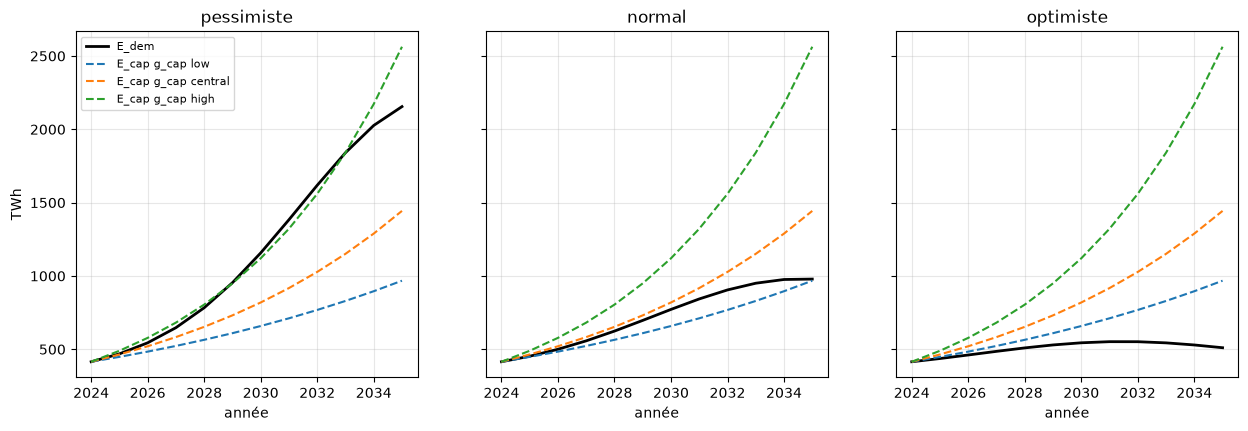

In [22]:
fig, axes = plt.subplots(1, len(M.SCENARIOS), figsize=(15, 4.5), sharey=True)
for ax, s in zip(axes, M.SCENARIOS):
    w = mur[s]
    ax.plot(M.ANNEES, w["E_dem"], "k-", lw=2, label="E_dem")
    for borne in S.BORNES:
        ax.plot(M.ANNEES, w[f"E_cap_{borne}"], "--", label=f"E_cap g_cap {borne}")
    ax.set(title=s, xlabel="année")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("TWh")
axes[0].legend(fontsize=8)
plt.show()

### 6.1 Stress test « miracle » : efficacité maximale admissible du parc

Question inverse : de combien le **parc** devrait-il gagner en efficacité pour que la demande
tienne sous une cible ? $E_{dem}(t)$ est strictement croissant en $T_{d,parc}$ (temps de
doublement de l'efficacité) : on calcule donc un **« T_d_max admissible »** (le parc doit doubler
d'efficacité **au plus tous les T\* ans**), pas un « T requis ». Cibles : borne basse IEA 2035
(niveau constant, lue dans `cibles_iea`) et $E_{cap}(t)$ pour chaque borne de $g_{cap}$.
Deux critères : **2035** (seul $E_{dem}(2035) \le C(2035)$) et **trajectoire** ($E_{dem}(t) \le C(t)$
chaque année 2025-2035). Le critère 2035 seul **masque une bosse** intermédiaire : voir la colonne
`max_E_wall`, l'excès maximal au-dessus de la cible sur la trajectoire avec ce T\*.

- **Hypothèse conditionnelle** : seul $T_{d,parc}$ bouge ; `g_tok`, `g_conv`, PUE, `E_DC0` restent
  aux valeurs du scénario, et $E_{conv}$ n'est **jamais** réduit par $T_d$.
- **Trois zones** selon la pointe du matériel (Epoch, statut S, valeurs divergentes selon les
  versions) : T\* en dessous de la pointe = « plus rapide que la pointe » (miracle) ;
  entre les deux bornes de la pointe = « le parc suit la pointe » (alors que la plage de
  $T_{d,parc}$ le suppose plus lent) ; au-dessus = « plausible ».
- **Ce n'est pas une prévision** : c'est la condition sous laquelle une cible serait tenue.

In [23]:
miracle = M.miracle_table()
pointe = S.raw_params()["miracle"]["pointe_epoch"]
display(miracle.set_index(["scenario", "cible", "critere"]))

T_star statut  T_d_parc  deja_tenue                       zone  max_E_wall
scenario   cible               critere                                                                                
pessimiste IEA bas 2035        2035           1.63     ok      3.00       False  plus_rapide_que_la_pointe       11.73
                               trajectoire    1.61     ok      3.00       False  plus_rapide_que_la_pointe        0.00
           E_cap g_cap low     2035           2.00     ok      3.00       False     le_parc_suit_la_pointe      150.94
                               trajectoire    1.53     ok      3.00       False  plus_rapide_que_la_pointe        0.00
           E_cap g_cap central 2035           2.46     ok      3.00       False     le_parc_suit_la_pointe      200.48
                               trajectoire    2.05     ok      3.00       False     le_parc_suit_la_pointe        0.00
           E_cap g_cap high    2035           3.29     ok      3.00        True                  plausible      270.73
                               trajectoire    2.88     ok      3.00       False     le_parc_suit_la_pointe        0.00
normal     IEA bas 2035        2035           2.21     ok      2.80       False     le_parc_suit_la_pointe       14.12
                               trajectoire    2.18     ok      2.80       False     le_parc_suit_la_pointe        0.00
           E_cap g_cap low     2035           2.78     ok      2.80       False     le_parc_suit_la_pointe      129.26
                               trajectoire    2.18     ok      2.80       False     le_parc_suit_la_pointe        0.00
           E_cap g_cap central 2035           3.62     ok      2.80        True                  plausible      157.21
                               trajectoire    3.04     ok      2.80        True                  plausible        0.00
           E_cap g_cap high    2035           5.62     ok      2.80        True                  plausible      201.13
                               trajectoire    4.87     ok      2.80        True                  plausible        0.00
optimiste  IEA bas 2035        2035           3.51     ok      2.50        True                  plausible       24.07
                               trajectoire    3.38     ok      2.50        True                  plausible        0.00
           E_cap g_cap low     2035           4.86     ok      2.50        True                  plausible      134.18
                               trajectoire    3.50     ok      2.50        True                  plausible        0.00
           E_cap g_cap central 2035           7.79     ok      2.50        True                  plausible      159.98
                               trajectoire    5.70     ok      2.50        True                  plausible        0.00
           E_cap g_cap high    2035          29.10     ok      2.50        True                  plausible      209.35
                               trajectoire   16.48     ok      2.50        True                  plausible        0.00

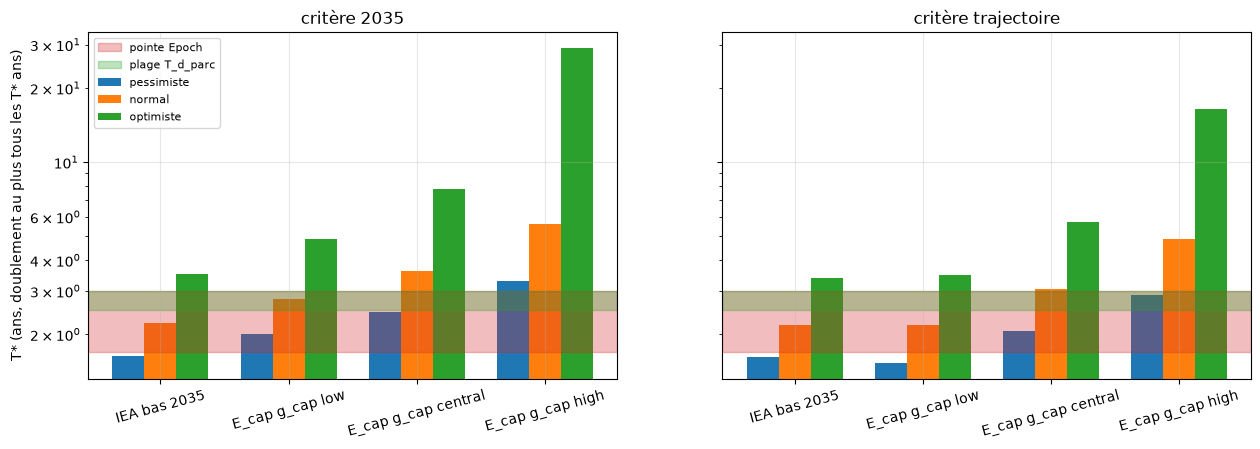

In [24]:
cibles_m = list(dict.fromkeys(miracle["cible"]))
largeur = 1 / (len(M.SCENARIOS) + 1)
fig, axes = plt.subplots(1, len(M.CRITERES), figsize=(15, 4.5), sharey=True)
for ax, critere in zip(axes, M.CRITERES):
    for k, s in enumerate(M.SCENARIOS):
        sel = miracle[(miracle["scenario"] == s) & (miracle["critere"] == critere)]
        sel = sel.set_index("cible").reindex(cibles_m)
        ax.bar([i + k * largeur for i in range(len(cibles_m))], sel["T_star"].fillna(0),
               width=largeur, label=s)
    ax.axhspan(pointe["low"]["valeur"], pointe["high"]["valeur"], color="tab:red", alpha=0.3,
               label="pointe Epoch")
    ax.axhspan(table[("T_d_parc", "low")], table[("T_d_parc", "high")], color="tab:green",
               alpha=0.3, label="plage T_d_parc")
    ax.set_xticks([i + largeur for i in range(len(cibles_m))], cibles_m, rotation=15)
    ax.set(title=f"critère {critere}", yscale="log")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("T* (ans, doublement au plus tous les T* ans)")
axes[0].legend(fontsize=8)
plt.show()

In [25]:
lignes_m = []
for _, r in miracle[miracle["critere"] == M.CRITERES[0]].iterrows():
    if r["cible"] == cibles_m[0]:
        lecture = f"T* = {r['T_star']:.2f} ans" if pd.notna(r["T_star"]) else r["statut"]
        lignes_m.append(f"- **{r['scenario']}** : {lecture} (zone : {r['zone']}) ; "
                      f"T_d_parc du scénario = {r['T_d_parc']:.2f} ans ; "
                      f"cible déjà tenue : {'oui' if r['deja_tenue'] else 'non'}.")
entete = f"Lecture, critère {M.CRITERES[0]}, cible {cibles_m[0]} (conditionnelle, pas une prévision) :"
display(Markdown(entete + "\n\n" + "\n".join(lignes_m)))

Lecture, critère 2035, cible IEA bas 2035 (conditionnelle, pas une prévision) :

- **pessimiste** : T* = 1.63 ans (zone : plus_rapide_que_la_pointe) ; T_d_parc du scénario = 3.00 ans ; cible déjà tenue : non.
- **normal** : T* = 2.21 ans (zone : le_parc_suit_la_pointe) ; T_d_parc du scénario = 2.80 ans ; cible déjà tenue : non.
- **optimiste** : T* = 3.51 ans (zone : plausible) ; T_d_parc du scénario = 2.50 ans ; cible déjà tenue : oui.

## 7. Monte Carlo et tornado

On propage les plages [low ; high] de `data/params.yaml` sur $E_{dem}$, CO2e et eau. Chaque
paramètre des jeux de scénarios est tiré **indépendamment** (un paramètre dont les bornes low et
high sont égales reste constant : la cellule suivante les liste) ; $g_{cap}$ et le contrôle
bottom-up sont hors tirage. Le noyau de calcul est celui de `project()` (aucune formule recopiée).

**Lecture** : l'éventail décrit la **dispersion induite par des plages choisies**, en majorité
des hypothèses H. Les quantiles sont des **parts des tirages**, pas des probabilités.

In [26]:
cfg = U.mc_config()
qs = cfg["quantiles"]
autre_loi = next(loi for loi in S.LOIS_MC if loi != cfg["loi"])
print(f"n_tirages = {cfg['n_tirages']} ; graine = {cfg['graine']} ; "
      f"loi de base = {cfg['loi']} ; loi de sensibilité = {autre_loi}")
print(f"quantiles = {qs} ; pas d'élasticité du tornado = {cfg['pas_elasticite']}")
LOIS = {cfg["loi"]: U.simulate(), autre_loi: U.simulate(loi=autre_loi)}
mc = LOIS[cfg["loi"]]
variables = [p for p in U.params_tires() if mc["params"][p].nunique() > 1]
constantes = [p for p in U.params_tires() if p not in variables]
print(f"Paramètres tirés : {len(variables)} ; constants (aucun tirage) : {', '.join(constantes)}")
print(f"Part des bornes par statut, paramètres tirés (loi {cfg['loi']}) :")
display(R.part_h(variables).to_frame())
print(f"Part de bornes H parmi les paramètres tirés : {R.part_h(variables)['H']:.0f} %")

n_tirages = 10000 ; graine = 20261014 ; loi de base = triangulaire ; loi de sensibilité = uniforme
quantiles = [0.05, 0.25, 0.5, 0.75, 0.95] ; pas d'élasticité du tornado = 0.1


Paramètres tirés : 14 ; constants (aucun tirage) : E_DC0, CI_ref, annee_ref_CI
Part des bornes par statut, paramètres tirés (loi triangulaire) :


,part_%
statut,
V,7.14
S,2.38
D,19.05
H,71.43


Part de bornes H parmi les paramètres tirés : 71 %


### 7.1 Éventail 2024-2035

Bandes intérieure et extérieure et médiane lues dans la configuration. Les scénarios optimiste et
pessimiste sont des **coins comonotones** (tous les paramètres à leur borne basse ou haute en
même temps) : sous tirages indépendants, ils tombent attendus **hors** de la bande extérieure.

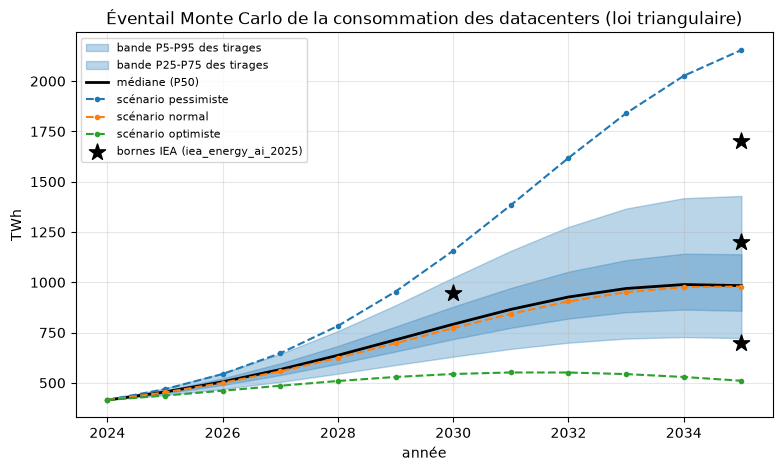

Scénario pessimiste dans la bande P5-P95 en 2035 : False
Scénario normal dans la bande P5-P95 en 2035 : True
Scénario optimiste dans la bande P5-P95 en 2035 : False


In [27]:
q = U.quantiles(mc, "E_dem")
ext, inte, med = (qs[0], qs[-1]), (qs[1], qs[-2]), qs[len(qs) // 2]
etiq = lambda a, b: f"P{100 * a:g}-P{100 * b:g}"
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(M.ANNEES, q[ext[0]], q[ext[1]], color="tab:blue", alpha=0.3,
                label=f"bande {etiq(*ext)} des tirages")
ax.fill_between(M.ANNEES, q[inte[0]], q[inte[1]], color="tab:blue", alpha=0.3,
                label=f"bande {etiq(*inte)} des tirages")
ax.plot(M.ANNEES, q[med], "k-", lw=2, label=f"médiane (P{100 * med:g})")
for s in M.SCENARIOS:
    ax.plot(M.ANNEES, res.loc[s, "E_dem"], "--", marker="o", ms=3, label=f"scénario {s}")
ax.scatter([c["annee"] for c in cibles], [c["valeur"] for c in cibles], marker="*", s=150,
           color="k", zorder=3, label="bornes IEA (iea_energy_ai_2025)")
ax.set(xlabel="année", ylabel="TWh",
       title=f"Éventail Monte Carlo de la consommation des datacenters (loi {cfg['loi']})")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()
lo, hi = q.loc[M.ANNEE1, ext[0]], q.loc[M.ANNEE1, ext[1]]
for s in M.SCENARIOS:
    dans = lo <= res.loc[(s, M.ANNEE1), "E_dem"] <= hi
    print(f"Scénario {s} dans la bande {etiq(*ext)} en {M.ANNEE1} : {dans}")

### 7.2 Distribution 2035 et position par rapport aux bornes IEA

Part des tirages sous la borne optimiste IEA, entre les deux bornes, au-dessus de la pessimiste.
La loi change ces parts de façon sensible : les deux lois sont montrées.

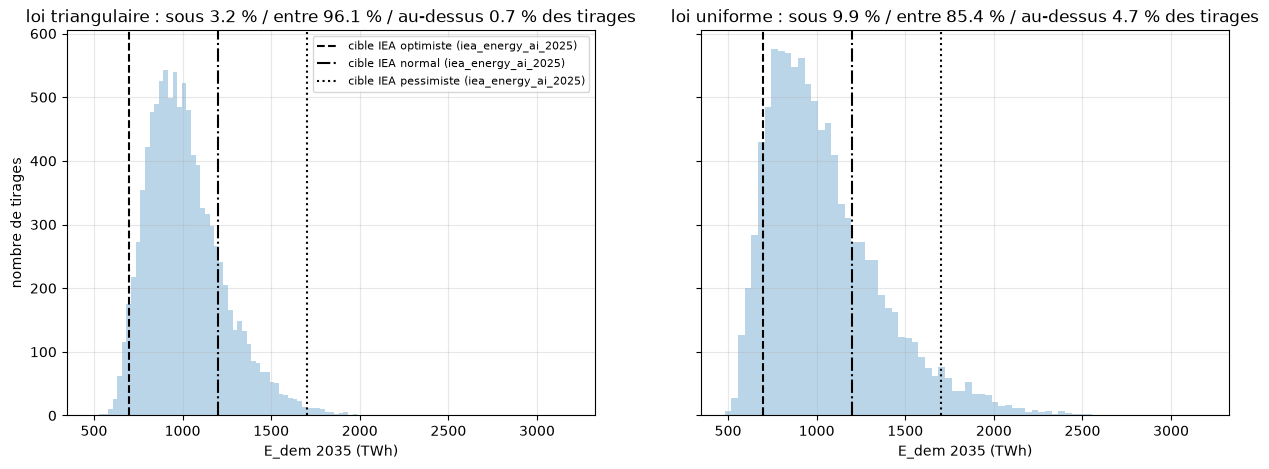

,sous_optimiste,entre,au_dessus_pessimiste
loi,,,
triangulaire,0.03,0.96,0.01
uniforme,0.10,0.85,0.05


In [28]:
fig, axes = plt.subplots(1, len(LOIS), figsize=(15, 5), sharex=True, sharey=True)
parts = {}
for ax, (loi, r) in zip(axes, LOIS.items()):
    parts[loi] = U.parts_vs_iea(r)
    ax.hist(r["E_dem"][M.ANNEE1], bins="auto", color="tab:blue", alpha=0.3)
    for cas, ls in (("optimiste", "--"), ("normal", "-."), ("pessimiste", ":")):
        ax.axvline(M.cible_iea(cas), color="k", ls=ls,
                   label=f"cible IEA {cas} (iea_energy_ai_2025)")
    p = parts[loi]
    ax.set(xlabel=f"E_dem {M.ANNEE1} (TWh)", title=(
        f"loi {loi} : sous {100 * p['sous_optimiste']:.1f} % / "
        f"entre {100 * p['entre']:.1f} % / "
        f"au-dessus {100 * p['au_dessus_pessimiste']:.1f} % des tirages"))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("nombre de tirages")
axes[0].legend(fontsize=8)
plt.show()
display(pd.DataFrame(parts).T.rename_axis("loi"))

### 7.3 Quantiles 2035 (TWh, Mt CO2e, hm³) et sensibilité à la loi

In [29]:
tab_q = pd.DataFrame({f"{s} ({u})": U.quantiles(mc, s).loc[M.ANNEE1] for s, u in UNITES.items()})
tab_q.index = [f"quantile {x}" for x in tab_q.index]
for sc in M.SCENARIOS:
    tab_q.loc[f"scénario {sc}"] = [res.loc[(sc, M.ANNEE1), col] for col in UNITES]
display(tab_q)
print(f"Sensibilité à la loi : quantiles {M.ANNEE1} (loi de base = {cfg['loi']})")
display(pd.concat(
    {s: pd.DataFrame({loi: U.quantiles(r, s).loc[M.ANNEE1] for loi, r in LOIS.items()}).T
     for s in UNITES},
    names=["sortie", "loi"],
))

,E_dem (TWh),CO2_Mt (Mt CO2e),W_hm3 (hm³)
quantile 0.05,722.58,277.77,"1,783.17"
quantile 0.25,858.52,330.79,"2,289.56"
quantile 0.5,983.52,381.43,"2,756.45"
quantile 0.75,"1,139.46",441.40,"3,343.73"
quantile 0.95,"1,429.51",556.61,"4,364.45"
scénario pessimiste,"2,154.83",938.66,"10,081.29"
scénario normal,978.79,385.41,"2,349.10"
scénario optimiste,510.57,172.44,701.18


Sensibilité à la loi : quantiles 2035 (loi de base = triangulaire)


0.05     0.25     0.50     0.75     0.95
sortie loi                                                      
E_dem  triangulaire   722.58   858.52   983.52 1,139.46 1,429.51
       uniforme       651.01   806.20   978.42 1,215.76 1,683.33
CO2_Mt triangulaire   277.77   330.79   381.43   441.40   556.61
       uniforme       245.49   307.31   375.99   469.21   651.62
W_hm3  triangulaire 1,783.17 2,289.56 2,756.45 3,343.73 4,364.45
       uniforme     1,613.83 2,287.37 2,948.59 3,843.44 5,485.47

### 7.4 Tornado (un paramètre à la fois autour du scénario normal) et Spearman

Chaque paramètre tiré non constant passe à low puis à high, les autres restant au central.
Barres : $y(low)$ et $y(high)$ **telles quelles**, sans réorientation (le sens varie selon le
paramètre). Tri par amplitude ; les amplitudes nulles restent en bas. La colonne `elasticite`
est la sensibilité locale intrinsèque, indépendante de la largeur de plage.

À droite, la corrélation de rang de Spearman **globale** sur les tirages : elle capte des
interactions que le tornado local ignore. Un écart de classement est un résultat, pas une
erreur. Ce n'est **pas** une décomposition de variance (ni $\rho^2$, ni Sobol).

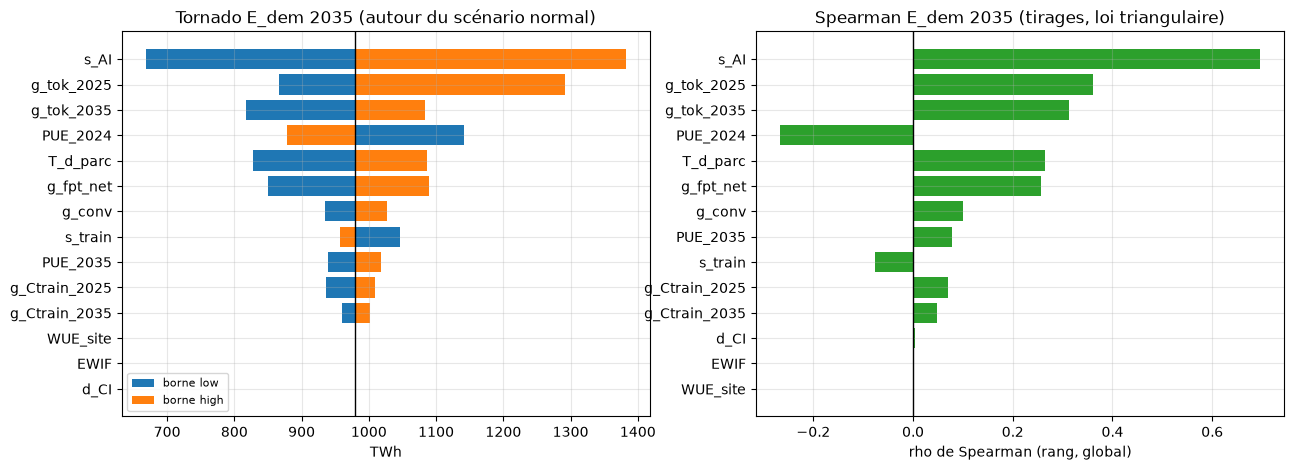

,y_low,y_central,y_high,amplitude,elasticite,rho_spearman
param,,,,,,
s_AI,668.20,978.79,"1,382.56",714.35,0.48,0.70
g_tok_2025,867.06,978.79,"1,292.02",424.96,2.62,0.36
g_tok_2035,816.92,978.79,"1,083.65",266.72,2.62,0.31
PUE_2024,"1,141.92",978.79,878.40,263.52,-1.01,-0.27
T_d_parc,827.48,978.79,"1,086.84",259.36,1.50,0.26
g_fpt_net,849.38,978.79,"1,089.41",240.03,5.90,0.26
g_conv,934.43,978.79,"1,027.68",93.25,0.14,0.10
s_train,"1,045.85",978.79,956.44,89.41,-0.16,-0.08
PUE_2035,939.64,978.79,"1,017.94",78.30,1.00,0.08


3 premiers au tornado  : ['s_AI', 'g_tok_2025', 'g_tok_2035']
3 premiers par Spearman : ['s_AI', 'g_tok_2025', 'g_tok_2035']
Même classement complet : False


In [30]:
def barres_tornado(ax, t, unite, titre):
    t = t.iloc[::-1]
    y_c = t["y_central"].iloc[0]
    ax.barh(t["param"], t["y_low"] - y_c, left=y_c, color="tab:blue", label="borne low")
    ax.barh(t["param"], t["y_high"] - y_c, left=y_c, color="tab:orange", label="borne high")
    ax.axvline(y_c, color="k", lw=1)
    ax.set(xlabel=unite, title=titre)
    ax.grid(alpha=0.3)


tor = {s: U.tornado(s) for s in UNITES}
sp = U.spearman(mc)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
barres_tornado(ax1, tor["E_dem"], "TWh", f"Tornado E_dem {M.ANNEE1} (autour du scénario normal)")
ax1.legend(fontsize=8)
sp_r = sp.iloc[::-1]
ax2.barh(sp_r.index, sp_r.values, color="tab:green")
ax2.axvline(0, color="k", lw=1)
ax2.set(xlabel="rho de Spearman (rang, global)",
        title=f"Spearman E_dem {M.ANNEE1} (tirages, loi {cfg['loi']})")
ax2.grid(alpha=0.3)
plt.show()
t_e = tor["E_dem"].set_index("param")
t_e["rho_spearman"] = sp
display(t_e)
top = 3
print(f"{top} premiers au tornado  :", list(t_e.index[:top]))
print(f"{top} premiers par Spearman :", list(sp.index[:top]))
print("Même classement complet :", list(t_e.index) == list(sp.index))

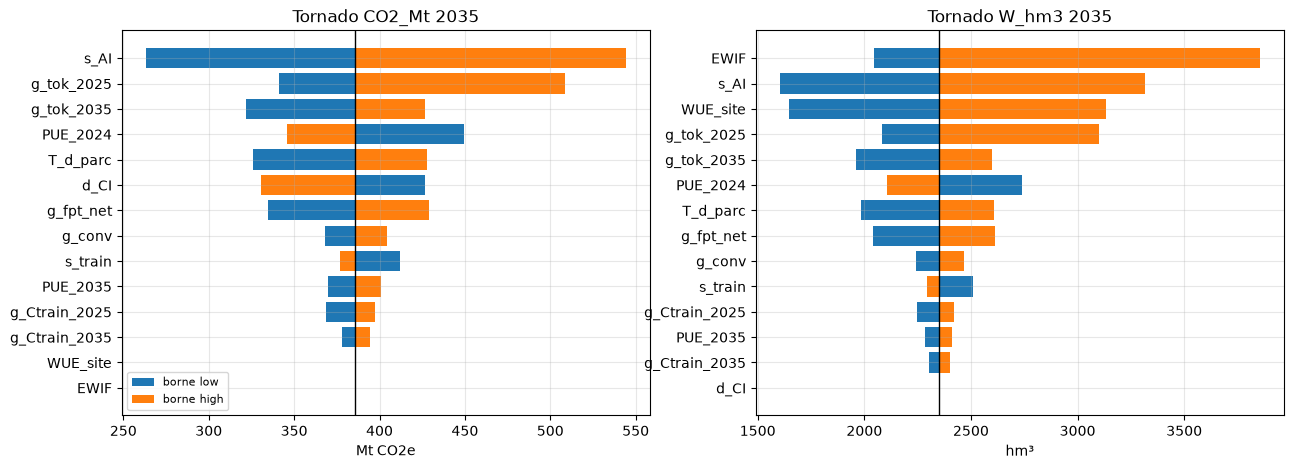

E_dem               CO2_Mt                W_hm3           
              amplitude elasticite amplitude elasticite amplitude elasticite
param                                                                       
s_AI             714.35       0.48    281.28       0.48  1,714.45       0.48
g_tok_2025       424.96       2.62    167.33       2.62  1,019.91       2.62
g_tok_2035       266.72       2.62    105.02       2.62    640.14       2.62
PUE_2024         263.52      -1.01    103.76      -1.01    632.45      -1.01
T_d_parc         259.36       1.50    102.13       1.50    622.48       1.50
g_fpt_net        240.03       5.90     94.51       5.90    576.07       5.90
g_conv            93.25       0.14     36.72       0.14    223.80       0.14
s_train           89.41      -0.16     35.21      -0.16    214.59      -0.16
PUE_2035          78.30       1.00     30.83       1.00    125.29       0.67
g_Ctrain_2025     72.67       0.51     28.61       0.51    174.40       0.51
g_Ctrain_2035     40.65       0.51     16.00       0.51     97.55       0.51
WUE_site           0.00       0.00      0.00       0.00  1,487.76       0.33
EWIF               0.00       0.00      0.00       0.00  1,810.76       0.67
d_CI               0.00       0.00     95.79      -0.15      0.00       0.00

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, s in zip(axes, ("CO2_Mt", "W_hm3")):
    barres_tornado(ax, tor[s], UNITES[s], f"Tornado {s} {M.ANNEE1}")
axes[0].legend(fontsize=8)
plt.show()
display(pd.concat({s: tor[s].set_index("param")[["amplitude", "elasticite"]] for s in UNITES},
                  axis=1))

### 7.5 Lecture

- **Part des tirages, pas probabilité** : les quantiles décrivent la dispersion induite par les
  plages de `data/params.yaml`, dont la majorité des bornes sont des hypothèses H (part calculée
  ci-dessus). Aucune probabilité n'est attachée à ces plages.
- **Indépendance** : les tirages sont sans corrélation. `g_tok_*` et `g_Ctrain_*` sont
  plausiblement corrélés positivement (même demande IA) : l'indépendance rétrécit probablement
  les queues. `PUE_2024` et `PUE_2035` sont tirés indépendamment, ce qui admet des couples
  incohérents (PUE_2024 bas, PUE_2035 haut).
- **Scénarios hors éventail** : attendu (coins comonotones contre tirages indépendants) ;
  les scénarios sont des enveloppes corrélées, le Monte Carlo suppose l'indépendance.
- **Classement dépendant des plages** : l'ordre du tornado reflète la largeur des plages
  choisies (`s_AI` domine, plage H/D), pas une élasticité intrinsèque : voir la colonne
  `elasticite`. Circularité des plages H assumée (CLAUDE.md).
- **Tornado local, Spearman global** : le premier est évalué autour du scénario normal, le
  second sur l'ensemble des tirages ; un écart de classement est un résultat.
- **Pas de décomposition de variance.**
- **Loi** : la sensibilité triangulaire / uniforme est affichée ; elle modifie sensiblement les
  parts de tirages par rapport aux bornes IEA.

## 8. CSO et backtest 2020-2025

Confronter le modèle et ses paramètres aux seules données **observées** disponibles, **sans
hindcast** : (1) pseudo-prévisions hors échantillon sur la série trimestrielle du CSO (Irlande) ;
(2) backtest de $d_{CI}$ sur la série annuelle d'Ember ; (3) le modèle global face au seul point
hors échantillon (l'année test) et à la croissance observée des premières années. Le modèle et
`data/params.yaml` ne sont **pas modifiés** par cette section : aucun ajustement des plages.

**Lecture** : le CSO décrit l'**Irlande**, quelques sites dominants, un périmètre détecté et
révisable. Il ne dit rien du monde ; c'est un témoin de dynamique. Chaque observation tracée
porte son statut (**V** lu à la source, **S** via relais, **D** dérivé) ; un taux dérivé prend le
statut effectif le plus faible de ses entrées.

### 8.1 Série CSO trimestrielle

Fichier figé : data/raw/cso_MEC02.csv (édition 2025, data.gov.ie maj 2026-07-07), téléchargé le 2026-10-16
sha256 : 6cc855c6e10f773fd4cfb5ba7a72b1e70e0d8c49d068411b3340b6545d566644
Source cso_irlande : lecture lu_source, période 2015Q1-2025Q4, trimestriel (annuel = somme des 4 trimestres)


Statut des taux CSO dérivés (statut, statut effectif) : [('D', 'V')]


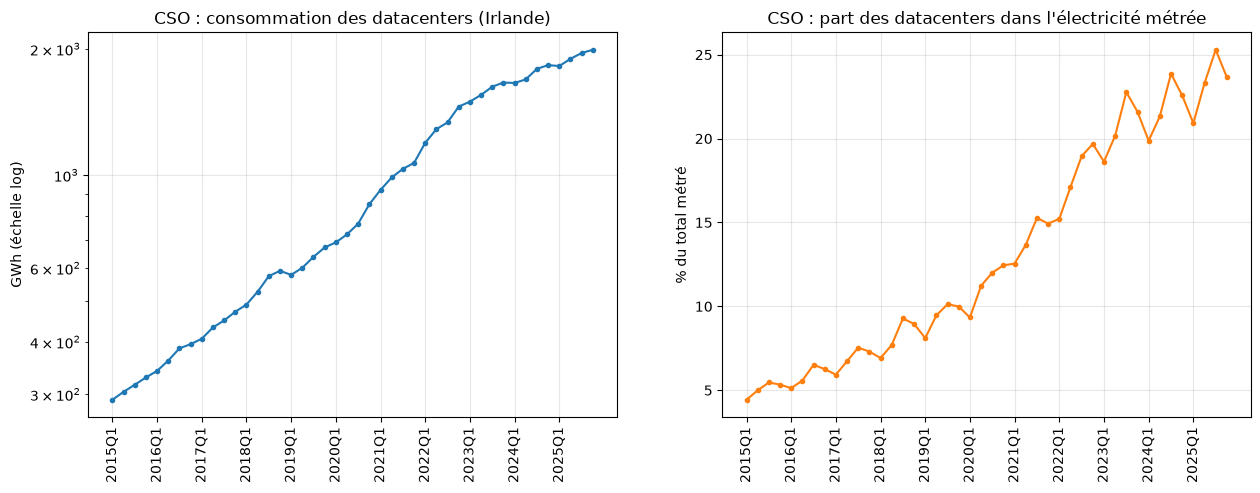

In [32]:
bcfg = B.bt_config()
reg = S.load_sources().set_index("id")
print(f"Fichier figé : {bcfg['cso_fichier']} ({bcfg['cso_edition']}), "
      f"téléchargé le {bcfg['cso_date_telechargement']}")
print(f"sha256 : {bcfg['cso_sha256']}")
print(f"Source cso_irlande : lecture {reg.loc['cso_irlande', 'statut_lecture']}, "
      f"période {reg.loc['cso_irlande', 'periode_donnees']}")
tri = B.cso_trimestriel()
ann = B.cso_annuel()
tobs = B.taux_observes()
statut_cso = tobs[tobs["serie"] == "cso_dc"][["statut", "statut_effectif"]].drop_duplicates()
print("Statut des taux CSO dérivés (statut, statut effectif) :",
      statut_cso.to_records(index=False).tolist())
pas = B.TRIMESTRES_PAR_AN
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.semilogy(range(len(tri)), tri["dc_gwh"], marker="o", ms=3)
ax1.set(ylabel="GWh (échelle log)", title="CSO : consommation des datacenters (Irlande)")
ax2.plot(range(len(tri)), 100 * tri["part"], marker="o", ms=3, color="tab:orange")
ax2.set(ylabel="% du total métré", title="CSO : part des datacenters dans l'électricité métrée")
for ax in (ax1, ax2):
    ax.set_xticks(range(0, len(tri), pas), tri["trimestre"].iloc[::pas])
    plt.setp(ax.get_xticklabels(), rotation="vertical")
    ax.grid(alpha=0.3)
plt.show()

In [33]:
ann["croissance_%"] = 100 * ann["croissance"]
display(ann.set_index("annee"))
print("Résidu log moyen par trimestre civil (régression croissante, toute la série) :")
display(B.residus_trimestre().rename_axis("trimestre civil").to_frame())

C03907V04659,dc_gwh,total_gwh,part,croissance,croissance_%
annee,,,,,
2015,1240,24599,0.05,NaN,NaN
2016,1483,25355,0.06,0.20,19.60
2017,1762,25726,0.07,0.19,18.81
2018,2183,26730,0.08,0.24,23.89
2019,2489,26504,0.09,0.14,14.02
2020,3031,27056,0.11,0.22,21.78
2021,4013,28506,0.14,0.32,32.40
2022,5274,29825,0.18,0.31,31.42
2023,6339,30581,0.21,0.20,20.19


Résidu log moyen par trimestre civil (régression croissante, toute la série) :


,residu_moyen
trimestre civil,
1,-0.00
2,0.00
3,0.00
4,-0.00


La **décélération** de la croissance annuelle (colonne `croissance_%`) est compatible avec une
contrainte d'offre (réseau), **non prouvée par ces données**. Le CSO annuel est la somme des
quatre trimestres (écart d'arrondi de 1 GWh avec la Table 1 du CSO). Aucune composante
saisonnière n'est modélisée : le résidu moyen par trimestre civil ci-dessus en donne l'ordre de
grandeur.

### 8.2 Pseudo-prévisions hors échantillon (origine glissante)

À chaque origine $o$, trois prévisionnistes sur $\log(\text{GWh})$ : **glissante** (OLS sur les
`fenetre` derniers trimestres, $o$ inclus), **croissante** (OLS depuis le premier trimestre) et
**naïve** (référence : dernier niveau prolongé au taux annuel réalisé). L'erreur est relative
($\hat y / y - 1$) ; les horizons sont en **trimestres**. La prévision à l'origine $o$ ne dépend
d'aucune donnée postérieure à $o$.

Origines de 2020Q1 ; fenêtre glissante = 12 points ; horizons (trimestres) = [4, 8]


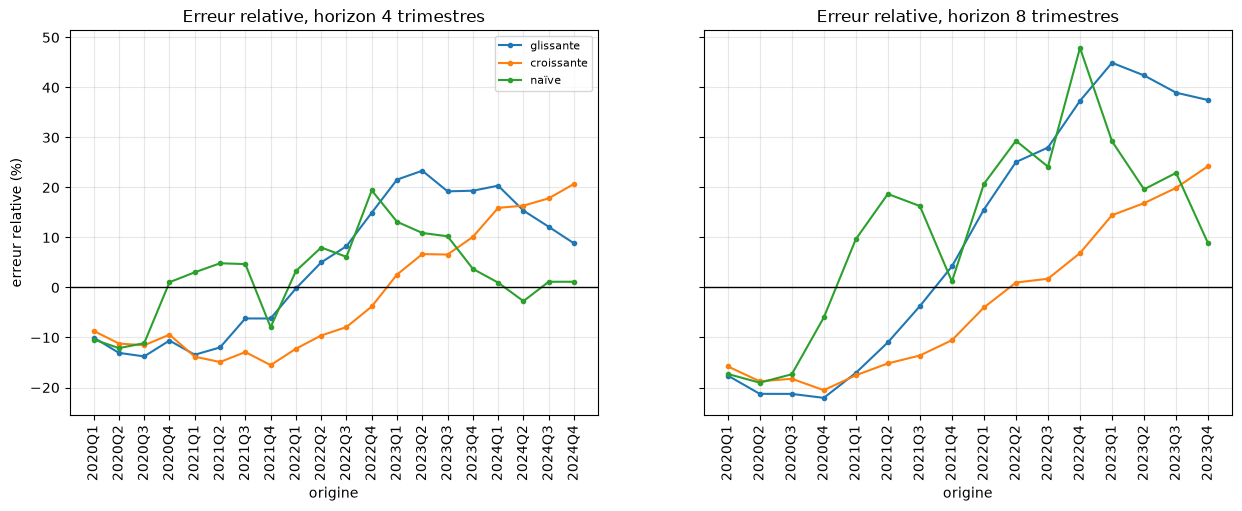

n  mape_pct  biais_pct
methode    h                         
glissante  4  20     12.69       4.14
           8  16     24.24       9.99
croissante 4  20     11.42      -1.74
           8  16     13.71      -3.07
naïve      4  20      6.80       2.37
           8  16     19.26      11.80

In [34]:
NOMS = {"glissante": "glissante", "croissante": "croissante", "naive": "naïve"}
pp = B.pseudo_previsions()
sc_bt = B.scores(pp)
pp["methode"] = pp["methode"].map(NOMS)
sc_aff = sc_bt.assign(methode=sc_bt["methode"].map(NOMS), mape_pct=100 * sc_bt["mape"],
                      biais_pct=100 * sc_bt["biais"])[["methode", "h", "n", "mape_pct", "biais_pct"]]
print(f"Origines de {bcfg['origine_debut']} ; fenêtre glissante = {bcfg['fenetre']} points ; "
      f"horizons (trimestres) = {bcfg['horizons']}")
fig, axes = plt.subplots(1, len(bcfg["horizons"]), figsize=(15, 5), sharey=True)
for ax, h in zip(axes, bcfg["horizons"]):
    for m, g in pp[pp["h"] == h].groupby("methode", sort=False):
        ax.plot(g["origine"], 100 * g["erreur"], marker="o", ms=3, label=m)
    ax.axhline(0, color="k", lw=1)
    ax.set(title=f"Erreur relative, horizon {h} trimestres", xlabel="origine")
    plt.setp(ax.get_xticklabels(), rotation="vertical")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("erreur relative (%)")
axes[0].legend(fontsize=8)
plt.show()
display(sc_aff.set_index(["methode", "h"]))

In [35]:
err_tab = 100 * pp.pivot_table(index="origine", columns=["h", "methode"], values="erreur")
print("Erreur relative (%) par origine :")
display(err_tab)

Erreur relative (%) par origine :


h                4                           8                 
methode croissante glissante  naïve croissante glissante  naïve
origine                                                        
2020Q1       -8.67    -10.00 -10.40     -15.78    -17.60 -17.29
2020Q2      -11.21    -13.08 -12.12     -18.76    -21.27 -19.04
2020Q3      -11.55    -13.78 -11.14     -18.26    -21.28 -17.35
2020Q4       -9.43    -10.61   1.05     -20.54    -22.07  -6.00
2021Q1      -13.84    -13.45   3.03     -17.56    -17.08   9.65
2021Q2      -14.90    -11.99   4.84     -15.18    -10.98  18.69
2021Q3      -12.91     -6.19   4.68     -13.60     -3.73  16.28
2021Q4      -15.53     -6.20  -7.94     -10.55      4.21   1.20
2022Q1      -12.25     -0.20   3.29      -4.00     15.58  20.70
2022Q2       -9.60      5.01   7.99       0.98     25.07  29.33
2022Q3       -7.92      8.26   6.13       1.74     27.97  24.15
2022Q4       -3.80     14.95  19.41       6.88     37.32  47.90
2023Q1        2.58     21.56  13.13      14.46     44.92  29.23
2023Q2        6.67     23.34  10.90      16.85     42.40  19.62
2023Q3        6.58     19.22  10.24      19.92     38.95  22.91
2023Q4       10.12     19.34   3.72      24.26     37.47   8.81
2024Q1       15.91     20.35   0.96        NaN       NaN    NaN
2024Q2       16.36     15.37  -2.73        NaN       NaN    NaN
2024Q3       17.82     12.13   1.14        NaN       NaN    NaN
2024Q4       20.70      8.82   1.14        NaN       NaN    NaN

**Dérive du taux** : taux annuel implicite des régressions ($e^{4b} - 1$, glissante et
croissante) à côté du taux annuel **réalisé** ($y_o / y_{o-4} - 1$), à chaque origine.

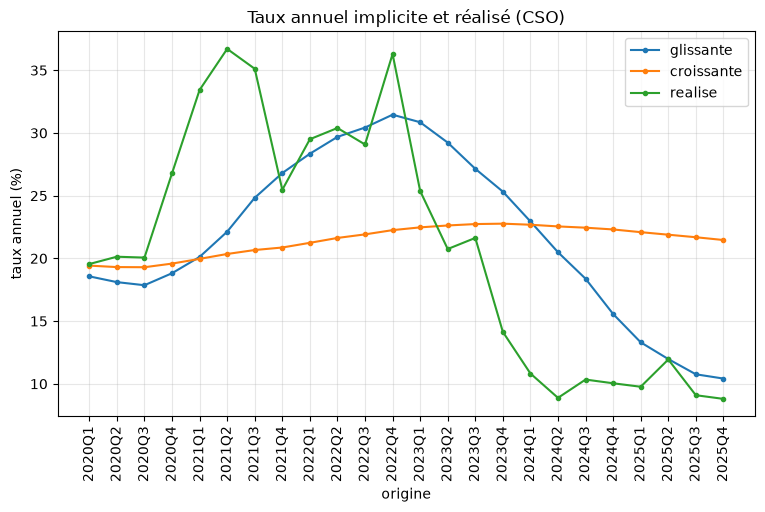

,glissante,croissante,realise
origine,,,
2020Q1,18.57,19.42,19.55
2020Q2,18.11,19.31,20.13
2020Q3,17.86,19.30,20.06
2020Q4,18.82,19.58,26.79
2021Q1,20.12,19.96,33.43
2021Q2,22.13,20.35,36.70
2021Q3,24.83,20.67,35.12
2021Q4,26.80,20.87,25.47
2022Q1,28.34,21.24,29.50


In [36]:
dt = B.derive_taux().set_index("origine")
fig, ax = plt.subplots(figsize=(9, 5))
for col in dt.columns:
    ax.plot(dt.index, 100 * dt[col], marker="o", ms=3, label=col)
ax.set(xlabel="origine", ylabel="taux annuel (%)", title="Taux annuel implicite et réalisé (CSO)")
plt.setp(ax.get_xticklabels(), rotation="vertical")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
display(100 * dt)

Les origines se **chevauchent** : les erreurs sont autocorrélées, donc $n$ surestime
l'information, et quelques années de données ne désignent pas de meilleure méthode.

### 8.3 Backtest de $d_{CI}$ (Ember)

(a) **Hors échantillon** : à chaque origine, $\hat d = 1 - e^{b}$ (OLS log-linéaire sur les
`fenetre_ci` points annuels précédents, origine incluse), comparé à la plage [low ; high] de
`d_CI`. (b) **Dans l'échantillon** : la forme $CI_{ref}(1 - d)^{t - t_{ref}}$ rétro-appliquée aux
trois bornes de $d_{CI}$.

Série Ember : statuts ['S'] ; sources ['ember_2025', 'owid_2026'] ; 11 points annuels ; fenêtre = 5 points
(a) d̂ glissant, hors échantillon, face à la plage [low ; high] de d_CI :


,d_hat,dans_plage,plage_low,plage_high
origine,,,,
2020,0.02,True,0.01,0.03
2021,0.02,True,0.01,0.03
2022,0.01,True,0.01,0.03
2023,0.01,True,0.01,0.03
2024,0.01,True,0.01,0.03


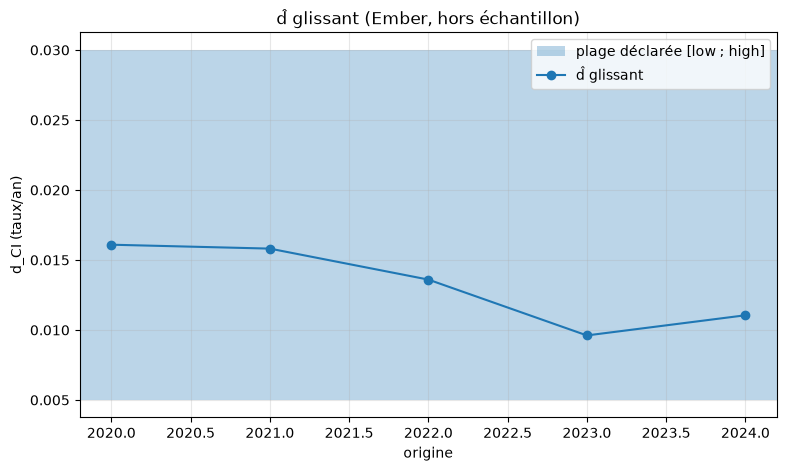

Erreur relative (%) de CI prévu, par origine et année :


annee,2021,2022,2023,2024,2025
origine,,,,,
2020,-1.33,-1.87,-2.18,-1.28,-0.16
2021,NaN,-1.36,-1.65,-0.72,0.44
2022,NaN,NaN,-0.68,0.49,1.89
2023,NaN,NaN,NaN,1.67,3.50
2024,NaN,NaN,NaN,NaN,2.58


In [37]:
bci = B.backtest_ci()
obs_e = B.observations("ember_ci_monde")
print(f"Série Ember : statuts {sorted(obs_e['statut'].unique())} ; sources "
      f"{sorted({i for x in obs_e['source_ids'] for i in x})} ; {len(obs_e)} points annuels ; "
      f"fenêtre = {bcfg['fenetre_ci']} points")
gl = bci["glissant"].set_index("origine")
d_low, d_high = table[("d_CI", "low")], table[("d_CI", "high")]
gl["plage_low"], gl["plage_high"] = d_low, d_high
print("(a) d̂ glissant, hors échantillon, face à la plage [low ; high] de d_CI :")
display(gl)
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhspan(d_low, d_high, alpha=0.3, label="plage déclarée [low ; high]")
ax.plot(gl.index, gl["d_hat"], marker="o", label="d̂ glissant")
ax.set(xlabel="origine", ylabel="d_CI (taux/an)", title="d̂ glissant (Ember, hors échantillon)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print("Erreur relative (%) de CI prévu, par origine et année :")
display(100 * bci["erreurs"].pivot(index="origine", columns="annee", values="erreur"))

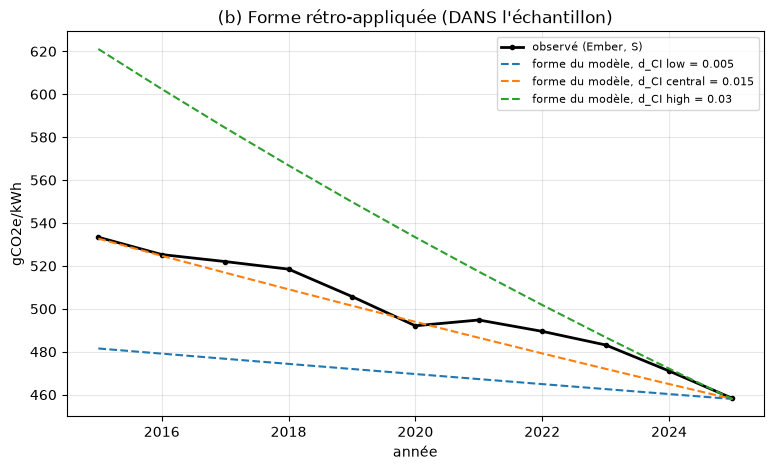

(b) Erreur relative (%) de la forme du modèle, DANS l'échantillon :


borne,low,central,high
annee,,,
2015,-9.72,-0.12,16.44
2016,-8.79,-0.11,14.69
2017,-8.68,-0.99,11.94
2018,-8.52,-1.81,9.32
2019,-6.68,-0.85,8.72
2020,-4.57,0.37,8.38
2021,-5.56,-1.67,4.55
2022,-5.02,-2.10,2.51
2023,-4.26,-2.30,0.74


In [38]:
forme = bci["forme_modele"]
fig, ax = plt.subplots(figsize=(9, 5))
obs_c = forme[forme["borne"] == S.BORNES[0]].set_index("annee")["ci_obs"]
ax.plot(obs_c.index, obs_c, "k-", lw=2, marker="o", ms=3, label=f"observé (Ember, {'/'.join(sorted(obs_e['statut'].unique()))})")
for borne in S.BORNES:
    f_b = forme[forme["borne"] == borne].set_index("annee")
    ax.plot(f_b.index, f_b["ci_mod"], "--",
            label=f"forme du modèle, d_CI {borne} = {f_b['d'].iloc[0]:g}")
ax.set(xlabel="année", ylabel="gCO2e/kWh",
       title="(b) Forme rétro-appliquée (DANS l'échantillon)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()
print("(b) Erreur relative (%) de la forme du modèle, DANS l'échantillon :")
display(100 * forme.pivot(index="annee", columns="borne", values="erreur")[list(S.BORNES)])

Le panneau (b) est **dans l'échantillon** : le $d_{CI}$ central est dérivé des mêmes points, il
ne valide donc pas la forme. « `dans_plage` » est en partie acquis par construction (plage H
large). Seul (a) est hors échantillon, sur un petit nombre de points.

### 8.4 Modèle global face à l'année test

Lecture fixée avant l'exécution : la comparaison
principale porte sur le **taux** de croissance de l'ancrage à l'année test (robuste à une révision
du niveau d'ancrage) ; le **niveau** vient ensuite, en secondaire. Si le taux observé est hors de
l'intervalle formé par le plus petit et le plus grand quantile de la configuration Monte Carlo,
le modèle est déclaré **non reproduit**, avec l'écart. Aucun ajustement des plages ou des
paramètres n'est fait ici. Le test n'est **pas aveugle** (voir 8.5) : le point de
l'année test n'est « hors échantillon » qu'au sens où il n'a pas servi à un calcul.

In [39]:
pt =B.point_2025(res=mc)
an = pt["annee"]
ligne_obs = tobs[(tobs["serie"] == "iea_monde") & (tobs["debut"] == M.ANNEE0)
                 & (tobs["fin"] == an)].iloc[0]
niv_all = B.observations("iea_monde")
ligne_niv = niv_all[niv_all["annee"] == an].iloc[0]
print(f"1. TAUX {M.ANNEE0} -> {an} (comparaison principale)")
lignes_taux = {f"scénario {s}": v for s, v in pt["taux_scenarios"].items()}
lignes_taux.update({f"quantile {q:g} des tirages": v for q, v in pt["taux_quantiles"].items()})
lignes_taux[f"OBSERVÉ IEA [{ligne_obs['statut_effectif']}] ({ligne_obs['edition']})"] = (
    pt["taux_observe"])
display((100 * pd.Series(lignes_taux)).to_frame(f"taux annuel {M.ANNEE0}->{an} (%)"))
print(f"Part des tirages dont le taux est >= au taux observé : {100 * pt['part_taux_ge']:.2f} %")

1. TAUX 2024 -> 2025 (comparaison principale)


,taux annuel 2024->2025 (%)
scénario pessimiste,12.94
scénario normal,9.08
scénario optimiste,5.30
quantile 0.05 des tirages,5.92
quantile 0.25 des tirages,7.96
quantile 0.5 des tirages,9.63
quantile 0.75 des tirages,11.39
quantile 0.95 des tirages,14.02
OBSERVÉ IEA [V] (IEA Key Questions 2026),17.00


Part des tirages dont le taux est >= au taux observé : 0.08 %


In [40]:
print(f"2. NIVEAU {an} (comparaison secondaire)")
niv_tab = pd.DataFrame(
    {"E_dem (TWh)": {**{f"scénario {s}": v for s, v in pt["niveaux_scenarios"].items()},
                     **{f"quantile {q:g} des tirages": v
                        for q, v in pt["niveaux_quantiles"].items()}},
     "écart relatif au niveau observé (%)": {
         **{f"scénario {s}": 100 * v for s, v in pt["ecart_niveau_scenarios"].items()},
         **{f"quantile {q:g} des tirages": 100 * v
            for q, v in pt["ecart_niveau_quantiles"].items()}}})
niv_tab.loc[f"OBSERVÉ IEA [{ligne_niv['statut']}] ({ligne_niv['edition']})"] = [
    pt["niveau_observe"], 0]
display(niv_tab)
print(f"Part des tirages <= niveau observé : {100 * pt['part_niveau_le']:.2f} % ; "
      f">= niveau observé : {100 * pt['part_niveau_ge']:.2f} %")

2. NIVEAU 2025 (comparaison secondaire)


,E_dem (TWh),écart relatif au niveau observé (%)
scénario pessimiste,468.72,-3.36
scénario normal,452.68,-6.66
scénario optimiste,436.99,-9.90
quantile 0.05 des tirages,439.56,-9.37
quantile 0.25 des tirages,448.02,-7.62
quantile 0.5 des tirages,454.95,-6.20
quantile 0.75 des tirages,462.28,-4.68
quantile 0.95 des tirages,473.19,-2.43
OBSERVÉ IEA [S] (IEA Key Questions 2026 (relais OWID)),485.00,0.00


Part des tirages <= niveau observé : 99.87 % ; >= niveau observé : 0.13 %


Éventail Monte Carlo 2024-2027 (TWh) :


,0.05,0.25,0.50,0.75,0.95
annee,,,,,
2024,415.00,415.00,415.00,415.00,415.00
2025,439.56,448.02,454.95,462.28,473.19
2026,469.68,489.29,505.27,522.54,548.93
2027,505.23,538.86,566.48,596.93,644.02


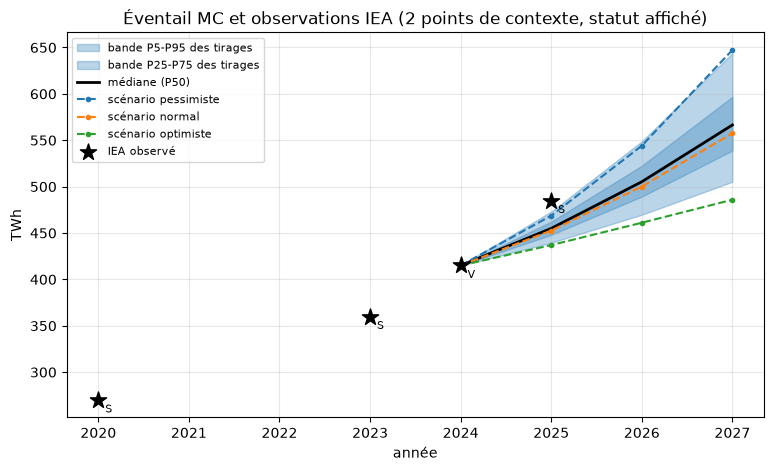

Observations IEA du graphique (2020 et 2023 : contexte, dans aucun calcul) :


,serie,annee,valeur,unite,statut,edition,source_ids
0,iea_monde,2020,270.00,TWh,S,IEA Key Questions 2026 (relais OWID),owid_2026
1,iea_monde,2023,360.00,TWh,S,"IEA 2026 (relais, édition non confirmée)",owid_2026
2,iea_monde,2024,415.00,TWh,V,Energy and AI 2025,iea_energy_ai_2025
3,iea_monde,2025,485.00,TWh,S,IEA Key Questions 2026 (relais OWID),"iea_key_questions_2026, owid_2026"


In [41]:
annees_p = list(range(M.ANNEE0, M.ANNEE0 + bcfg["annees_premieres"] + 1))
print(f"Éventail Monte Carlo {annees_p[0]}-{annees_p[-1]} (TWh) :")
display(q.loc[annees_p])
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(annees_p, q.loc[annees_p, ext[0]], q.loc[annees_p, ext[1]], color="tab:blue",
                alpha=0.3, label=f"bande {etiq(*ext)} des tirages")
ax.fill_between(annees_p, q.loc[annees_p, inte[0]], q.loc[annees_p, inte[1]], color="tab:blue",
                alpha=0.3, label=f"bande {etiq(*inte)} des tirages")
ax.plot(annees_p, q.loc[annees_p, med], "k-", lw=2, label=f"médiane (P{100 * med:g})")
for s in M.SCENARIOS:
    ax.plot(annees_p, res.loc[s, "E_dem"].loc[annees_p], "--", marker="o", ms=3,
            label=f"scénario {s}")
ax.scatter(niv_all["annee"], niv_all["valeur"], marker="*", s=150, color="k", zorder=3,
           label="IEA observé")
for _, r_ in niv_all.iterrows():
    ax.annotate(f"{r_['statut']}", (r_["annee"], r_["valeur"]), textcoords="offset points",
                xytext=(5, -9), fontsize=8)
ax.set(xlabel="année", ylabel="TWh",
       title="Éventail MC et observations IEA (2 points de contexte, statut affiché)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()
print("Observations IEA du graphique (2020 et 2023 : contexte, dans aucun calcul) :")
display(niv_all.assign(source_ids=niv_all["source_ids"].map(", ".join))[
    ["serie", "annee", "valeur", "unite", "statut", "edition", "source_ids"]])

In [42]:
print(f"Taux annuel moyen {M.ANNEE0} -> {M.ANNEE0 + bcfg['annees_premieres']} "
      "(croissance des premières années, modèle) :")
tm = B.taux_modele(res=mc).set_index("ligne")
display(100 * tm.drop(columns="type"))
tx_aff = tobs.assign(taux_pct=100 * tobs["taux"], source_ids=tobs["source_ids"].map(", ".join))
print("Taux observés ou dérivés (zone, période, édition, statut) ; AUCUNE ligne n'est une cible :")
with pd.option_context("display.max_colwidth", 110):
    display(tx_aff[["serie", "zone", "debut", "fin", "taux_pct", "edition", "statut",
                    "statut_effectif", "formule", "source_ids"]])

Taux annuel moyen 2024 -> 2027 (croissance des premières années, modèle) :


,taux_test,taux_premieres
ligne,,
pessimiste,12.94,15.97
normal,9.08,10.34
optimiste,5.30,5.40
q0.05,5.92,6.78
q0.25,7.96,9.10
q0.5,9.63,10.93
q0.75,11.39,12.88
q0.95,14.02,15.78


Taux observés ou dérivés (zone, période, édition, statut) ; AUCUNE ligne n'est une cible :


,serie,zone,debut,fin,taux_pct,edition,statut,statut_effectif,formule,source_ids
0,iea_monde,Monde,2019,2024,12.00,Energy and AI 2025,V,V,valeur publiée,iea_energy_ai_2025
1,iea_monde,Monde,2024,2025,17.00,IEA Key Questions 2026,V,V,valeur publiée,iea_key_questions_2026
2,iea_monde,Monde,2018,2023,10.50,IEA-4E 2025,D,D,valeur publiée,iea4e_2025
3,lbnl_us,États-Unis,2014,2023,13.13,"LBNL, 2024 United States Data Center Energy Usage Report (Shehabi et al.)",D,S,(v_fin / v_debut)^(1 / (fin - debut)) - 1,lbnl_2024
4,cso_dc,Irlande,2019,2024,22.88,"édition 2025, data.gov.ie maj 2026-07-07",D,V,(v_fin / v_debut)^(1 / (fin - debut)) - 1,cso_irlande
5,cso_dc,Irlande,2023,2024,10.02,"édition 2025, data.gov.ie maj 2026-07-07",D,V,(v_fin / v_debut)^(1 / (fin - debut)) - 1,cso_irlande
6,cso_dc,Irlande,2024,2025,9.87,"édition 2025, data.gov.ie maj 2026-07-07",D,V,(v_fin / v_debut)^(1 / (fin - debut)) - 1,cso_irlande
7,cso_dc,Irlande,2018,2023,23.76,"édition 2025, data.gov.ie maj 2026-07-07",D,V,(v_fin / v_debut)^(1 / (fin - debut)) - 1,cso_irlande


In [43]:
pct = lambda x: f"{100 * x:.2f} %"
bas, haut = pt["intervalle_taux"]
plage = (f"[{pct(bas)} ; {pct(haut)}] (quantiles P{100 * min(qs):g} à P{100 * max(qs):g} "
         "des tirages)")
st = ligne_obs["statut_effectif"]
if pt["hors_intervalle"]:
    au_dessus = pt["taux_observe"] > haut
    sens = "au-dessus" if au_dessus else "en dessous"
    erreur_croissance = ("sous-estimation" if au_dessus else "surestimation")
    lecture_taux = (
        f"**Taux {M.ANNEE0}→{an}.** Le taux observé IEA ({pct(pt['taux_observe'])}, [{st}]) est "
        f"{sens} de l'intervalle {plage} : **non reproduit par le modèle**. Écart à la borne la "
        f"plus proche de l'intervalle : {100 * abs(pt['ecart_taux']):.2f} points de pourcentage. "
        f"Part des tirages dont le taux est supérieur ou égal au taux observé : "
        f"{pct(pt['part_taux_ge'])}. Interprétations possibles, **non tranchées** : "
        f"{erreur_croissance} de la croissance de court terme dans les plages H (`g_tok_2025`, "
        "`s_AI`, ...) ; révision du niveau d'ancrage de l'année de base ; différence d'édition "
        "IEA entre l'ancrage et le point de l'année test. Aucun ajustement n'est fait ici."
    )
else:
    lecture_taux = (
        f"**Taux {M.ANNEE0}→{an}.** Le taux observé IEA ({pct(pt['taux_observe'])}, [{st}]) est "
        f"dans l'intervalle {plage} : le modèle n'est pas contredit sur ce point. Cela ne le "
        "**valide** pas (un seul point, plages H larges). Aucun ajustement n'est fait ici."
    )
niv_q = pt["niveaux_quantiles"]
canal = "relais" if ligne_niv["statut"] == "S" else "lu à la source"
niv_hors = not niv_q.min() <= pt["niveau_observe"] <= niv_q.max()
position_niv = ("hors de l'étendue" if niv_hors else "dans l'étendue")
lecture_niveau = (
    f"**Niveau {an} (secondaire).** Le niveau observé ({pt['niveau_observe']:.0f} TWh, "
    f"[{ligne_niv['statut']}], {canal}) est {position_niv} des quantiles du modèle "
    f"[{niv_q.min():.0f} ; {niv_q.max():.0f}] TWh. Part des tirages inférieure ou égale au niveau "
    f"observé : {pct(pt['part_niveau_le'])} ; supérieure ou égale : {pct(pt['part_niveau_ge'])}. "
    "Le niveau dépend de l'ancrage de l'année de base (révisable) et d'une édition IEA "
    "différente : il est moins robuste que le taux."
)
display(Markdown(lecture_taux))
display(Markdown(lecture_niveau))

**Taux 2024→2025.** Le taux observé IEA (17.00 %, [V]) est au-dessus de l'intervalle [5.92 % ; 14.02 %] (quantiles P5 à P95 des tirages) : **non reproduit par le modèle**. Écart à la borne la plus proche de l'intervalle : 2.98 points de pourcentage. Part des tirages dont le taux est supérieur ou égal au taux observé : 0.08 %. Interprétations possibles, **non tranchées** : sous-estimation de la croissance de court terme dans les plages H (`g_tok_2025`, `s_AI`, ...) ; révision du niveau d'ancrage de l'année de base ; différence d'édition IEA entre l'ancrage et le point de l'année test. Aucun ajustement n'est fait ici.

**Niveau 2025 (secondaire).** Le niveau observé (485 TWh, [S], relais) est hors de l'étendue des quantiles du modèle [440 ; 473] TWh. Part des tirages inférieure ou égale au niveau observé : 99.87 % ; supérieure ou égale : 0.13 %. Le niveau dépend de l'ancrage de l'année de base (révisable) et d'une édition IEA différente : il est moins robuste que le taux.

### 8.5 Lecture

- **Lecture du point 2025** : voir ci-dessus (taux d'abord, puis niveau) ; elle découle des
  valeurs calculées, et aucun paramètre n'a été ajusté après coup.
- **Honnêteté** : le taux IEA de l'année test était déjà connu quand les plages H ont été
  choisies ; il n'a **pas** été utilisé volontairement, mais le test **n'est pas aveugle**.
- **CSO** : Irlande, quelques sites dominants, périmètre détecté et révisable ; témoin de
  dynamique, rien sur le monde. La décélération est compatible avec une contrainte d'offre
  (réseau), **non prouvée par ces données**.
- **Pseudo-prévisions** : origines chevauchantes, erreurs autocorrélées, $n$ surestime
  l'information ; quelques années ne désignent pas de meilleure méthode.
- **Backtest $d_{CI}$** : (b) est **dans l'échantillon** (le $d_{CI}$ central est dérivé des
  mêmes points) et ne valide pas la forme ; `dans_plage` est en partie acquis par construction ;
  seul (a) est hors échantillon, sur un petit nombre de points.
- **Éditions IEA** : les séries viennent de deux éditions, non homogènes.
- **Vocabulaire** : les quantiles sont des **parts des tirages**, pas des probabilités ;
  **aucune méthode n'est validée** par un point isolé ou par quelques points annuels.

## 9. Limites

- **Annuel seulement** : IEA, LBNL, Shift, RTE, Epoch sont annuels ou événementiels ; jamais
  d'interpolation annuel -> mensuel.
- **Périmètres IEA / Shift** : l'écart 415 TWh (2024) contre 530 TWh (2023) n'est pas établi (un
  autre relais donne 420 TWh en 2024) ; ne pas les mélanger sans relire le PDF. Google (0,26 mL,
  WUE fixe 1,15 L/kWh) et Mistral (45 mL, cycle de vie) ne se mélangent pas non plus.
- **6ND et 2N FLOP/token** : relations vérifiées dans Kaplan 2020 ; « 20
  tokens par paramètre » (Hoffmann 2022) non énoncé tel quel [NT] ; 6ND ignore la R&D, les essais
  ratés et l'inférence.
- **Scope 2 location-based** en base ; market-based en sensibilité seulement (non traité ici).
- **Circularité des plages H** : les plages de croissance sont choisies pour encadrer des ordres
  de grandeur IEA ; ce n'est pas une mesure.
- **Intensité carbone** : moyenne mondiale appliquée à des datacenters concentrés.
- Parts de base ($s_{AI}$, $s_{train}$, $PUE_{2024}$) figées au central dans les trois scénarios
  (libres dans le Monte Carlo).
- **Monte Carlo (section 7)** : l'éventail est **conditionnel** à $E_{DC0}$ et $CI_{ref}$
  constants (l'écart IEA / Shift n'est pas établi) ; $g_{cap}$ est exclu (stress test du mur) ;
  l'incertitude de forme du modèle n'est pas propagée ; les tirages sont indépendants (pas de
  corrélations, cf. 7.5) ; les plages sont en majorité H : dispersion induite, pas probabilité.
- **CSO et backtest (section 8)** :
  - *Vintage CSO* : fichier figé (édition et empreinte affichées en 8.1) ; le CSO révise ses
    derniers trimestres (sous-estimation initiale du dernier exercice).
  - *Saisonnalité* : aucune composante saisonnière dans les prévisions ; le résidu par trimestre
    civil (8.1) en donne l'ordre de grandeur.
  - *Irlande ≠ monde* : quelques sites dominants, périmètre détecté et révisable ; le CSO est un
    témoin de dynamique, pas une mesure du monde.
  - *Éditions IEA* : les séries IEA viennent de deux éditions, non homogènes ; un relais (OWID)
    porte les niveaux de contexte et le niveau de l'année test.
  - *Ember 2025* : partiellement estimé ; série relayée (dénominateur Ember).
  - Le point de l'année test est **un seul point** ; aucun ajustement n'a été fait
    et le test n'est pas aveugle (8.5).
- **Horizon** : ancrage 2024 -> 2035 = 11 ans (9 ans depuis 2026, 10 depuis la dernière
  observation, 2025). L'IEA-4E recommande d'éviter les projections à plus de 5 ans (p. vi,
  p. 46) : notre horizon va à l'encontre ; l'éventail 2035 est un exercice de sensibilité, pas
  une prévision.
- **Méthode** : l'IEA-4E juge de faible qualité les extrapolations temporelles par proxy (p. 9,
  p. 39) ; notre Kaya est une extrapolation de facteurs, pas un bottom-up de parc.
- **Ancrage 2025** : une sensibilité ancrée sur le niveau 2025 [S] (485 TWh) n'est pas calculée
  ; elle déplacerait vraisemblablement l'éventail vers le haut (485 [S]
  au-dessus des trajectoires du modèle en 2025) ; non calculé.
- **Pas de recalage** : les plages H ne sont pas ajustées au point 2025.
- **Dispersion de la littérature** : facteur ~40 entre les estimations 2030 (p. iv, IEA-4E
  2025) ; nos trois scénarios n'en couvrent qu'une partie.

## 10. Conclusion

Texte généré par les cellules de code ci-dessous, à partir des objets calculés plus haut : aucun
résultat n'est écrit à la main dans le markdown.

In [44]:
fin = M.ANNEE1
txt_sc = " ; ".join(
    f"{s} {ecarts.loc[s, 'modele_TWh']:.0f} TWh (borne IEA {ecarts.loc[s, 'cible_IEA_TWh']:.0f}, "
    f"écart {ecarts.loc[s, 'ecart_%']:+.0f} %)" for s in M.SCENARIOS)
q_fin = q.loc[fin]
co2_fin = U.quantiles(mc, "CO2_Mt").loc[fin]
eau_fin = U.quantiles(mc, "W_hm3").loc[fin]
nn = res.loc[("normal", fin)]

bas_b0, haut_b0 = pt["intervalle_taux"]
if pt["hors_intervalle"]:
    verdict_b0 = (
        f"le taux observé IEA {M.ANNEE0}→{an} ({pct(pt['taux_observe'])}) est hors de l'intervalle "
        f"{etiq(*ext)} des tirages [{pct(bas_b0)} ; {pct(haut_b0)}] : **non reproduit par le modèle**")
else:
    verdict_b0 = (
        f"le taux observé IEA {M.ANNEE0}→{an} ({pct(pt['taux_observe'])}) est dans l'intervalle "
        f"{etiq(*ext)} des tirages [{pct(bas_b0)} ; {pct(haut_b0)}] : le modèle n'est pas "
        "contredit, sans être validé")

mir = miracle[(miracle["critere"] == M.CRITERES[-1]) & (miracle["cible"] == cibles_m[0])]
mir = mir.set_index("scenario")
txt_mir = " ; ".join(
    f"{s} T* = {mir.loc[s, 'T_star']:.2f} ans (zone : {mir.loc[s, 'zone'].replace('_', ' ')})"
    if pd.notna(mir.loc[s, "T_star"]) else f"{s} : {mir.loc[s, 'statut']}" for s in M.SCENARIOS)
rapides = [s for s in M.SCENARIOS if mir.loc[s, "zone"] == M.ZONES[0]]
txt_rapides = (f"Le scénario {', '.join(rapides)} exige d'aller plus vite que la pointe Epoch."
               if rapides else "Aucun scénario n'exige d'aller plus vite que la pointe Epoch.")

inc_n = tables["normal"].loc[fin]
part_h_tires = R.part_h(variables)["H"]
part_h_tout = R.bornes_par_statut().loc["H", "part_%"]

puces = [
    (f"**Scénarios {fin}** : {txt_sc}. Ils sont **comparés** aux bornes IEA, non calés : "
    "l'écart est un résultat, le calage n'existe que comme diagnostic."),
    (f"**Éventail Monte Carlo {fin}** : {etiq(*ext)} = [{q_fin[ext[0]]:.0f} ; {q_fin[ext[1]]:.0f}] "
    f"TWh (médiane {q_fin[med]:.0f}). Ce sont des **parts des tirages**, pas des probabilités ; "
    "les scénarios optimiste et pessimiste, coins comonotones, sont attendus hors de cette bande."),
    (f"**CO2e (scope 2 location-based) et eau {fin}**, scénario normal : {nn['CO2_Mt']:.0f} Mt CO2e "
    f"(éventail {etiq(*ext)} [{co2_fin[ext[0]]:.0f} ; {co2_fin[ext[1]]:.0f}] Mt) et "
    f"{nn['W_hm3']:.0f} hm³ d'eau consommée ([{eau_fin[ext[0]]:.0f} ; {eau_fin[ext[1]]:.0f}] hm³). "
    "Le market-based reste une sensibilité, non traitée."),
    (f"**Backtest {M.ANNEE0}→{an}** : {verdict_b0}. Le test est **non aveugle** : ce taux était "
    "connu avant le choix des plages H. **Aucun recalage** n'a été fait."),
    (f"**Miracle** (critère trajectoire, cible = borne basse IEA {fin}, "
    f"{M.cible_iea('optimiste'):.0f} TWh) : T_d_max admissible, le parc doit doubler d'efficacité "
    f"au plus tous les T* ans : {txt_mir}. {txt_rapides} Ce n'est **pas une prévision** : c'est la "
    "condition sous laquelle la cible serait tenue."),
    (f"**Carbone incorporé du matériel IT** : sous-ensemble du scope 3, ordre de grandeur, affiché "
    f"**à part**, jamais additionné au CO2e scope 2 : {inc_n['CO2_incorpore_Mt_low']:.1f} à "
    f"{inc_n['CO2_incorpore_Mt_high']:.1f} Mt en {fin} (scénario normal, bornes basse à haute). "
    "Le scope 3 complet d'un hyperscaler est plus grand."),
    (f"**Horizon** : {fin - M.ANNEE0} ans, contre la recommandation IEA-4E de ne pas dépasser "
    "5 ans ; l'éventail est un exercice de **sensibilité**, pas une prévision."),
    (f"**Traçabilité** : {part_h_tires:.0f} % des bornes des paramètres tirés sont des hypothèses H "
    f"({part_h_tout:.0f} % sur l'ensemble des paramètres) ; les plages H de croissance encadrent "
    "des ordres de grandeur IEA : circularité assumée, ce n'est pas une mesure."),
]
display(Markdown("\n".join(f"- {p}" for p in puces)))

- **Scénarios 2035** : pessimiste 2155 TWh (borne IEA 1700, écart +27 %) ; normal 979 TWh (borne IEA 1200, écart -18 %) ; optimiste 511 TWh (borne IEA 700, écart -27 %). Ils sont **comparés** aux bornes IEA, non calés : l'écart est un résultat, le calage n'existe que comme diagnostic.
- **Éventail Monte Carlo 2035** : P5-P95 = [723 ; 1430] TWh (médiane 984). Ce sont des **parts des tirages**, pas des probabilités ; les scénarios optimiste et pessimiste, coins comonotones, sont attendus hors de cette bande.
- **CO2e (scope 2 location-based) et eau 2035**, scénario normal : 385 Mt CO2e (éventail P5-P95 [278 ; 557] Mt) et 2349 hm³ d'eau consommée ([1783 ; 4364] hm³). Le market-based reste une sensibilité, non traitée.
- **Backtest 2024→2025** : le taux observé IEA 2024→2025 (17.00 %) est hors de l'intervalle P5-P95 des tirages [5.92 % ; 14.02 %] : **non reproduit par le modèle**. Le test est **non aveugle** : ce taux était connu avant le choix des plages H. **Aucun recalage** n'a été fait.
- **Miracle** (critère trajectoire, cible = borne basse IEA 2035, 700 TWh) : T_d_max admissible, le parc doit doubler d'efficacité au plus tous les T* ans : pessimiste T* = 1.61 ans (zone : plus rapide que la pointe) ; normal T* = 2.18 ans (zone : le parc suit la pointe) ; optimiste T* = 3.38 ans (zone : plausible). Le scénario pessimiste exige d'aller plus vite que la pointe Epoch. Ce n'est **pas une prévision** : c'est la condition sous laquelle la cible serait tenue.
- **Carbone incorporé du matériel IT** : sous-ensemble du scope 3, ordre de grandeur, affiché **à part**, jamais additionné au CO2e scope 2 : 15.2 à 67.2 Mt en 2035 (scénario normal, bornes basse à haute). Le scope 3 complet d'un hyperscaler est plus grand.
- **Horizon** : 11 ans, contre la recommandation IEA-4E de ne pas dépasser 5 ans ; l'éventail est un exercice de **sensibilité**, pas une prévision.
- **Traçabilité** : 71 % des bornes des paramètres tirés sont des hypothèses H (68 % sur l'ensemble des paramètres) ; les plages H de croissance encadrent des ordres de grandeur IEA : circularité assumée, ce n'est pas une mesure.

In [45]:
display(Markdown(
    "**Ce que le modèle ne dit pas**\n\n"
    "- Aucune probabilité : les quantiles sont des parts de tirages sur des plages en majorité H.\n"
    "- Aucune prévision : horizon bien au-delà de ce que l'IEA-4E recommande, méthode par proxy "
    "(extrapolation de facteurs) jugée de faible qualité par l'IEA-4E, pas un bottom-up de parc.\n"
    "- Aucun recalage après ce test et aucune sensibilité d'ancrage 2025 calculée.\n"
    "- Pas de scope 3 complet : seul un sous-ensemble (carbone incorporé du matériel IT) est "
    "chiffré, à part.\n"
    "- Pas de mesure du monde par le CSO (Irlande) : témoin de dynamique seulement."
))

**Ce que le modèle ne dit pas**

- Aucune probabilité : les quantiles sont des parts de tirages sur des plages en majorité H.
- Aucune prévision : horizon bien au-delà de ce que l'IEA-4E recommande, méthode par proxy (extrapolation de facteurs) jugée de faible qualité par l'IEA-4E, pas un bottom-up de parc.
- Aucun recalage après ce test et aucune sensibilité d'ancrage 2025 calculée.
- Pas de scope 3 complet : seul un sous-ensemble (carbone incorporé du matériel IT) est chiffré, à part.
- Pas de mesure du monde par le CSO (Irlande) : témoin de dynamique seulement.